In [2]:
!pip install -q \
    "pandas==2.2.3" \
    "transformers==4.51.3" \
    "datasets==3.5.0" \
    "accelerate==1.6.0" \
    "peft==0.15.2" \
    "trl==0.17.0" \
    "bitsandbytes==0.45.5" \
    "huggingface_hub==0.36.2" \
    sentencepiece scikit-learn matplotlib

In [3]:
import torch
import transformers
import huggingface_hub
import pandas
import peft
import trl
import fsspec

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("Pandas:", pandas.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("Fsspec:", fsspec.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Transformers: 4.51.3
Hugging Face Hub: 0.36.2
Pandas: 2.2.3
PEFT: 0.15.2
TRL: 0.17.0
Fsspec: 2024.12.0
GPU available: True
GPU: Tesla T4


In [4]:
# CELL 3: IMPORT LIBRARIES AND VERIFY ENVIRONMENT

import os
import gc
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import transformers
import huggingface_hub
import datasets
import accelerate
import peft
import trl
import bitsandbytes

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("=" * 55)
print("ENVIRONMENT VERIFICATION")
print("=" * 55)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("Pandas:", pd.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("WARNING: Enable GPU under Runtime > Change runtime type.")

print("\nEnvironment verification completed.")

ENVIRONMENT VERIFICATION
PyTorch: 2.14.1+cu130
Transformers: 4.51.3
Hugging Face Hub: 0.36.2
Pandas: 2.2.3
Datasets: 3.5.0
Accelerate: 1.6.0
PEFT: 0.15.2
TRL: 0.17.0

GPU available: True
GPU: Tesla T4
GPU memory: 14.56 GB

Environment verification completed.


In [5]:
# CELL 4: REPRODUCIBILITY CONFIGURATION

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Random seed:", SEED)
print("Reproducibility configuration completed.")

Random seed: 42
Reproducibility configuration completed.


In [6]:
# CELL 5: GPU MEMORY CHECK

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU not detected. Go to Runtime > Change runtime type > T4 GPU."
    )

gpu_name = torch.cuda.get_device_name(0)
total_memory = torch.cuda.get_device_properties(0).total_memory / (1024**3)
free_memory, total_memory_bytes = torch.cuda.mem_get_info()
free_memory_gb = free_memory / (1024**3)

print("GPU:", gpu_name)
print(f"Total GPU memory: {total_memory:.2f} GB")
print(f"Free GPU memory: {free_memory_gb:.2f} GB")
print("GPU verification completed.")

GPU: Tesla T4
Total GPU memory: 14.56 GB
Free GPU memory: 14.46 GB
GPU verification completed.


In [7]:
# CELL 6: REPAIR HUGGING FACE AUTHENTICATION

!pip uninstall -y huggingface_hub

!pip install --no-cache-dir --force-reinstall \
    "huggingface_hub==0.30.2"

Found existing installation: huggingface_hub 0.36.2
Uninstalling huggingface_hub-0.36.2:
  Successfully uninstalled huggingface_hub-0.36.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 838.5/838.5 kB 84.8 MB/s  0:00:00
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.16.0
    Uninstalling typing_extensions-4.16.0:
      Successfully uninstalled typing_extensions-4.16.0
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.67.3
    Uninstalling tqdm-4.67.3:
      Successfully uninstalled tqdm-4.67.3
  Attempting uninstall: pyyaml
    Found existing installation: PyYAML 6.0.3
    Uninstalling PyYAML-6.0.3:
      Successfully uninstalled PyYAML-6.0.3
  Attempting uninstall: packaging
    Found existing installation: packaging 26.3
    Uninstalling packaging-26.3:
      Successf

In [1]:
# ============================================================
# CELL 6: HUGGING FACE AUTHENTICATION
# Research: Implicit Sentiment Detection in Amharic Text
# Model: Google Gemma 3 4B Instruct
# ============================================================

from getpass import getpass
from huggingface_hub import login, whoami

print("=" * 60)
print("HUGGING FACE AUTHENTICATION")
print("=" * 60)

# Step 1: Enter your Hugging Face token securely
HF_TOKEN = getpass("Enter your Hugging Face READ token: ")

# Step 2: Validate token input
if not HF_TOKEN.strip():
    raise ValueError("No token entered. Please enter your READ token.")

# Step 3: Authenticate
login(
    token=HF_TOKEN.strip(),
    add_to_git_credential=False
)

# Step 4: Verify authentication
user_info = whoami(token=HF_TOKEN.strip())

# Step 5: Display account information
print("\n" + "=" * 60)
print("AUTHENTICATION SUCCESSFUL")
print("=" * 60)

print("Hugging Face username:", user_info["name"])
print("Model access target: google/gemma-3-4b-it")
print("Token permission: READ")
print("=" * 60)

# Keep the token available for later model downloads
print("Authentication verification completed.")

HUGGING FACE AUTHENTICATION
Enter your Hugging Face READ token: ··········

AUTHENTICATION SUCCESSFUL
Hugging Face username: LingerewBantie
Model access target: google/gemma-3-4b-it
Token permission: READ
Authentication verification completed.


In [2]:
# ============================================================
# CELL 7: VERIFY GEMMA 3 MODEL ACCESS
# ============================================================

from huggingface_hub import model_info

MODEL_ID = "google/gemma-3-4b-it"

print("=" * 60)
print("VERIFYING GEMMA 3 MODEL ACCESS")
print("=" * 60)

try:
    model = model_info(
        MODEL_ID,
        token=HF_TOKEN
    )

    print("Model access: SUCCESS")
    print("Model ID:", model.id)
    print("Model author:", model.author)
    print("Model pipeline:", model.pipeline_tag)
    print("Model:", MODEL_ID)

except Exception as e:
    print("MODEL ACCESS FAILED")
    print("Error:", str(e))
    raise

print("=" * 60)
print("CELL 7 COMPLETED")
print("=" * 60)

VERIFYING GEMMA 3 MODEL ACCESS
Model access: SUCCESS
Model ID: google/gemma-3-4b-it
Model author: google
Model pipeline: image-text-to-text
Model: google/gemma-3-4b-it
CELL 7 COMPLETED


In [3]:
# ============================================================
# CELL 8: UPLOAD AND LOAD AMHARIC SENTIMENT DATASET
# Research: Implicit Sentiment Detection in Amharic Text
# ============================================================

from google.colab import files
import pandas as pd
import io

print("=" * 60)
print("UPLOAD AMHARIC SENTIMENT DATASET")
print("=" * 60)

# Upload CSV file
uploaded = files.upload()

if not uploaded:
    raise ValueError("No dataset uploaded.")

# Read uploaded CSV
file_name = next(iter(uploaded))

df = pd.read_csv(
    io.BytesIO(uploaded[file_name]),
    encoding="utf-8"
)

print("\nDataset loaded successfully!")
print("File:", file_name)
print("Dataset shape:", df.shape)

# Display dataset columns
print("\nDataset columns:")
print(df.columns.tolist())

# Display first five records
print("\nFirst five records:")
display(df.head())

print("\nDataset loading completed.")

UPLOAD AMHARIC SENTIMENT DATASET


Saving Amharic_Implicit_Sentiment.csv to Amharic_Implicit_Sentiment.csv

Dataset loaded successfully!
File: Amharic_Implicit_Sentiment.csv
Dataset shape: (4225, 4)

Dataset columns:
['id', 'text_am', 'sentiment_label', 'split']

First five records:


,id,text_am,sentiment_label,split
0,AMIS0001,የተላከው ፋይል ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,test
1,AMIS0002,የጠየቅሁት እርዳታ ከጠበቅሁት በላይ ረዳኝ።,Positive,train
2,AMIS0003,ሆስፒታሉ ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,train
3,AMIS0004,መጽሐፉ በጊዜው ስለደረሰ ሌላ ዕቅድ መቀየር አልነበረብኝም።,Positive,train
4,AMIS0005,ቤቱ ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,train



Dataset loading completed.


In [5]:
# ============================================================
# CELL 9: DATASET VALIDATION
# ============================================================

print("=" * 60)
print("AMHARIC SENTIMENT DATASET VALIDATION")
print("=" * 60)

# Required columns
required_columns = [
    "id",
    "text_am",
    "sentiment_label",
    "split"
]

# Check columns
missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Clean whitespace without changing labels
for col in ["text_am", "sentiment_label", "split"]:
    df[col] = df[col].astype("string").str.strip()

# Check missing values
print("\nMissing values:")
print(df[required_columns].isnull().sum())

# Check duplicate IDs
print("\nDuplicate IDs:", df["id"].duplicated().sum())

# Check dataset size
print("\nTotal sentences:", len(df))

# Label distribution
print("\nSentiment label distribution:")
display(df["sentiment_label"].value_counts())

# Split distribution
print("\nDataset split distribution:")
display(df["split"].value_counts())

# Label distribution by split
print("\nSentiment distribution by split:")
display(pd.crosstab(df["split"], df["sentiment_label"]))

# Check expected labels
expected_labels = {"Positive", "Negative", "Neutral"}
actual_labels = set(df["sentiment_label"].dropna().unique())

if actual_labels != expected_labels:
    raise ValueError(
        f"Unexpected labels. Found: {actual_labels}"
    )

# Check expected splits
expected_splits = {"train", "validation", "test"}
actual_splits = set(df["split"].dropna().unique())

if actual_splits != expected_splits:
    raise ValueError(
        f"Unexpected splits. Found: {actual_splits}"
    )

print("\nDATASET VALIDATION COMPLETED.")


AMHARIC SENTIMENT DATASET VALIDATION

Missing values:
id                 0
text_am            0
sentiment_label    0
split              0
dtype: int64

Duplicate IDs: 0

Total sentences: 4225

Sentiment label distribution:


,count
sentiment_label,
Positive,1409
Negative,1408
Neutral,1408



Dataset split distribution:


,count
split,
train,3380
test,423
validation,422



Sentiment distribution by split:


sentiment_label,Negative,Neutral,Positive
split,,,
test,141,141,141
train,1126,1127,1127
validation,141,140,141



DATASET VALIDATION COMPLETED.


In [6]:
# ============================================================
# CELL 10: DUPLICATE AND DATA LEAKAGE ANALYSIS
# ============================================================

print("=" * 65)
print("DUPLICATE AND DATA LEAKAGE ANALYSIS")
print("=" * 65)

# 1. Exact duplicate sentences
duplicate_texts = df[
    df["text_am"].duplicated(keep=False)
].sort_values("text_am")

print("\n1. Total exact duplicate rows:")
print(len(duplicate_texts))

# 2. Unique duplicated sentences
print("\n2. Number of unique duplicated sentences:")
print(duplicate_texts["text_am"].nunique())

# 3. Duplicate sentences across dataset splits
split_counts = (
    df.groupby("text_am")["split"]
    .nunique()
)

cross_split_texts = split_counts[split_counts > 1]

print("\n3. Sentences appearing across multiple splits:")
print(len(cross_split_texts))

# 4. Duplicate examples
print("\n4. Duplicate sentence examples:")
if not duplicate_texts.empty:
    display(
        duplicate_texts[
            ["id", "text_am", "sentiment_label", "split"]
        ].head(20)
    )
else:
    print("No exact duplicate sentences found.")

# 5. Conflicting labels for identical sentences
label_counts = (
    df.groupby("text_am")["sentiment_label"]
    .nunique()
)

conflicting_texts = label_counts[label_counts > 1]

print("\n5. Identical sentences with conflicting sentiment labels:")
print(len(conflicting_texts))

# 6. Preserve original dataset
print("\n6. Original dataset remains unchanged.")
print("Total records:", len(df))

print("\nDUPLICATE ANALYSIS COMPLETED.")

DUPLICATE AND DATA LEAKAGE ANALYSIS

1. Total exact duplicate rows:
0

2. Number of unique duplicated sentences:
0

3. Sentences appearing across multiple splits:
0

4. Duplicate sentence examples:
No exact duplicate sentences found.

5. Identical sentences with conflicting sentiment labels:
0

6. Original dataset remains unchanged.
Total records: 4225

DUPLICATE ANALYSIS COMPLETED.


In [7]:
# ============================================================
# CELL 11: CREATE DATASET SPLITS
# ============================================================

print("=" * 65)
print("CREATING TRAINING, VALIDATION AND TEST DATASETS")
print("=" * 65)

# Create separate datasets using the original split column
train_df = df[df["split"] == "train"].copy().reset_index(drop=True)

val_df = df[df["split"] == "validation"].copy().reset_index(drop=True)

test_df = df[df["split"] == "test"].copy().reset_index(drop=True)

# Verify all splits contain records
assert len(train_df) > 0, "Training dataset is empty."
assert len(val_df) > 0, "Validation dataset is empty."
assert len(test_df) > 0, "Test dataset is empty."

# Verify total records
assert len(train_df) + len(val_df) + len(test_df) == len(df)

# Display dataset sizes
print("\nDataset sizes:")
print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Test records:", len(test_df))
print("Total records:", len(df))

# Display split percentages
print("\nSplit percentages:")
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    percentage = len(data) / len(df) * 100
    print(f"{name}: {percentage:.2f}%")

# Display sentiment distribution
print("\nTraining label distribution:")
display(train_df["sentiment_label"].value_counts())

print("\nValidation label distribution:")
display(val_df["sentiment_label"].value_counts())

print("\nTest label distribution:")
display(test_df["sentiment_label"].value_counts())

# Verify no missing text or labels
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    assert data["text_am"].notna().all(), f"{name}: missing text."
    assert data["sentiment_label"].notna().all(), f"{name}: missing labels."

print("\nCELL 11 COMPLETED SUCCESSFULLY.")

CREATING TRAINING, VALIDATION AND TEST DATASETS

Dataset sizes:
Training records: 3380
Validation records: 422
Test records: 423
Total records: 4225

Split percentages:
Training: 80.00%
Validation: 9.99%
Test: 10.01%

Training label distribution:


,count
sentiment_label,
Positive,1127
Neutral,1127
Negative,1126



Validation label distribution:


,count
sentiment_label,
Positive,141
Negative,141
Neutral,140



Test label distribution:


,count
sentiment_label,
Positive,141
Negative,141
Neutral,141



CELL 11 COMPLETED SUCCESSFULLY.


In [8]:
# ============================================================
# CELL 12: PREPARE GEMMA 3 TRAINING DATA
# ============================================================

import pandas as pd

LABELS = ["Positive", "Negative", "Neutral"]

SYSTEM_PROMPT = """
You are an expert Amharic sentiment analysis model.
Analyze the implicit sentiment expressed in the Amharic text.
Consider contextual meaning, implied opinions, and emotional intention.
Do not classify based only on individual positive or negative words.
Return exactly one label:
Positive, Negative, or Neutral.
Do not provide explanations.
"""

def create_messages(row):
    return [
        {
            "role": "system",
            "content": SYSTEM_PROMPT.strip()
        },
        {
            "role": "user",
            "content": (
                "Classify the implicit sentiment of this Amharic sentence:\n"
                f"{row['text_am']}"
            )
        },
        {
            "role": "assistant",
            "content": row["sentiment_label"]
        }
    ]

# Validate labels before formatting
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    invalid = set(data["sentiment_label"].unique()) - set(LABELS)
    if invalid:
        raise ValueError(f"{name} contains invalid labels: {invalid}")

# Prepare each split
train_df["messages"] = train_df.apply(create_messages, axis=1)
val_df["messages"] = val_df.apply(create_messages, axis=1)
test_df["messages"] = test_df.apply(create_messages, axis=1)

print("=" * 60)
print("GEMMA 3 DATA PREPARATION COMPLETED")
print("=" * 60)

print("Training examples:", len(train_df))
print("Validation examples:", len(val_df))
print("Test examples:", len(test_df))

print("\nExample training record:")
print(train_df.iloc[0]["messages"])

print("\nOriginal sentiment labels preserved.")

GEMMA 3 DATA PREPARATION COMPLETED
Training examples: 3380
Validation examples: 422
Test examples: 423

Example training record:
[{'role': 'system', 'content': 'You are an expert Amharic sentiment analysis model.\nAnalyze the implicit sentiment expressed in the Amharic text.\nConsider contextual meaning, implied opinions, and emotional intention.\nDo not classify based only on individual positive or negative words.\nReturn exactly one label:\nPositive, Negative, or Neutral.\nDo not provide explanations.'}, {'role': 'user', 'content': 'Classify the implicit sentiment of this Amharic sentence:\nየጠየቅሁት እርዳታ ከጠበቅሁት በላይ ረዳኝ።'}, {'role': 'assistant', 'content': 'Positive'}]

Original sentiment labels preserved.


In [9]:
# ============================================================
# CELL 13: LOAD GEMMA 3 TOKENIZER
# ============================================================

from transformers import AutoTokenizer

MODEL_ID = "google/gemma-3-4b-it"

print("=" * 60)
print("LOADING GEMMA 3 TOKENIZER")
print("=" * 60)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    token=HF_TOKEN
)

print("Tokenizer loaded successfully.")
print("Model:", MODEL_ID)
print("Vocabulary size:", len(tokenizer))
print("Padding token:", tokenizer.pad_token)
print("EOS token:", tokenizer.eos_token)

# Test the official chat template
sample_messages = train_df.iloc[0]["messages"][:2]

formatted_prompt = tokenizer.apply_chat_template(
    sample_messages,
    tokenize=False,
    add_generation_prompt=True
)

print("\nExample formatted Amharic prompt:")
print(formatted_prompt)

# Check tokenization length
sample_tokens = tokenizer(
    train_df.iloc[0]["text_am"],
    add_special_tokens=False
)

print("\nSample sentence token count:", len(sample_tokens["input_ids"]))

print("\nCELL 13 COMPLETED.")

LOADING GEMMA 3 TOKENIZER


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

Tokenizer loaded successfully.
Model: google/gemma-3-4b-it
Vocabulary size: 262145
Padding token: <pad>
EOS token: <eos>

Example formatted Amharic prompt:
<bos><start_of_turn>user
You are an expert Amharic sentiment analysis model.
Analyze the implicit sentiment expressed in the Amharic text.
Consider contextual meaning, implied opinions, and emotional intention.
Do not classify based only on individual positive or negative words.
Return exactly one label:
Positive, Negative, or Neutral.
Do not provide explanations.

Classify the implicit sentiment of this Amharic sentence:
የጠየቅሁት እርዳታ ከጠበቅሁት በላይ ረዳኝ።<end_of_turn>
<start_of_turn>model


Sample sentence token count: 19

CELL 13 COMPLETED.


AMHARIC TOKEN LENGTH ANALYSIS

Training sentence token statistics:
Number of sentences: 3380
Minimum: 11
Maximum: 36
Mean: 21.23
Median: 21.0
90th percentile: 27.0
95th percentile: 29.0
99th percentile: 31.0

Estimated truncation:
Limit 128: 0 sentences (0.00%)
Limit 256: 0 sentences (0.00%)
Limit 384: 0 sentences (0.00%)
Limit 512: 0 sentences (0.00%)


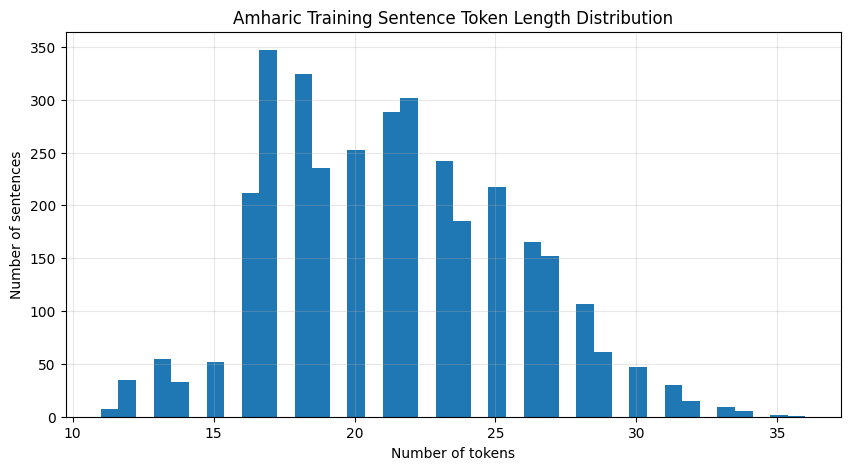


CELL 14 COMPLETED.


In [10]:
# ============================================================
# CELL 14: TOKEN LENGTH ANALYSIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 60)
print("AMHARIC TOKEN LENGTH ANALYSIS")
print("=" * 60)

def calculate_token_lengths(data):
    lengths = []

    for text in data["text_am"]:
        tokens = tokenizer(
            str(text),
            add_special_tokens=False
        )
        lengths.append(len(tokens["input_ids"]))

    return np.array(lengths)

# Analyze training sentences
train_lengths = calculate_token_lengths(train_df)

# Statistics
print("\nTraining sentence token statistics:")
print("Number of sentences:", len(train_lengths))
print("Minimum:", train_lengths.min())
print("Maximum:", train_lengths.max())
print("Mean:", round(train_lengths.mean(), 2))
print("Median:", np.median(train_lengths))
print("90th percentile:", np.percentile(train_lengths, 90))
print("95th percentile:", np.percentile(train_lengths, 95))
print("99th percentile:", np.percentile(train_lengths, 99))

# Analyze truncation thresholds
print("\nEstimated truncation:")
for limit in [128, 256, 384, 512]:
    truncated = np.sum(train_lengths > limit)
    percentage = truncated / len(train_lengths) * 100
    print(
        f"Limit {limit}: {truncated} sentences "
        f"({percentage:.2f}%)"
    )

# Plot distribution
plt.figure(figsize=(10, 5))
plt.hist(train_lengths, bins=40)
plt.xlabel("Number of tokens")
plt.ylabel("Number of sentences")
plt.title("Amharic Training Sentence Token Length Distribution")
plt.grid(alpha=0.3)
plt.show()

print("\nCELL 14 COMPLETED.")

In [11]:
# ============================================================
# CELL 15: SELECT MAXIMUM SEQUENCE LENGTH
# ============================================================

MAX_LENGTH = 256

# Calculate percentage of sentences exceeding selected length
truncated_count = np.sum(train_lengths > MAX_LENGTH)
truncated_percentage = (
    truncated_count / len(train_lengths)
) * 100

print("=" * 60)
print("SEQUENCE LENGTH CONFIGURATION")
print("=" * 60)

print("Selected maximum length:", MAX_LENGTH)
print("Training sentences:", len(train_lengths))
print("Sentences exceeding limit:", truncated_count)
print(f"Potential truncation: {truncated_percentage:.2f}%")

if truncated_percentage > 5:
    print("\nWARNING: More than 5% of sentences exceed this limit.")
    print("Consider increasing MAX_LENGTH after checking GPU capacity.")
else:
    print("\nSelected length is suitable based on the training text lengths.")

print("\nCELL 15 COMPLETED.")

SEQUENCE LENGTH CONFIGURATION
Selected maximum length: 256
Training sentences: 3380
Sentences exceeding limit: 0
Potential truncation: 0.00%

Selected length is suitable based on the training text lengths.

CELL 15 COMPLETED.


In [12]:
# ============================================================
# CELL 16: TOKENIZE DATASETS FOR GEMMA 3
# ============================================================

from datasets import Dataset

def tokenize_example(example):
    formatted_text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )

    encoded = tokenizer(
        formatted_text,
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False
    )

    # Causal language modeling: predict the complete conversation
    encoded["labels"] = encoded["input_ids"].copy()

    return encoded


def prepare_dataset(data, split_name):
    print(f"\nTokenizing {split_name} dataset...")

    dataset = Dataset.from_pandas(
        data[["messages"]].reset_index(drop=True),
        preserve_index=False
    )

    tokenized = dataset.map(
        tokenize_example,
        remove_columns=dataset.column_names,
        desc=f"Tokenizing {split_name}"
    )

    print(f"{split_name} examples: {len(tokenized)}")
    print("Example token count:", len(tokenized[0]["input_ids"]))

    return tokenized


train_tokenized = prepare_dataset(train_df, "Training")
val_tokenized = prepare_dataset(val_df, "Validation")

# Test data is deliberately not tokenized for training.
# It remains untouched for final evaluation.

print("\nTRAINING DATA:", len(train_tokenized))
print("VALIDATION DATA:", len(val_tokenized))
print("TEST DATA RESERVED:", len(test_df))

print("\nCELL 16 COMPLETED.")


Tokenizing Training dataset...


Tokenizing Training:   0%|          | 0/3380 [00:00<?, ? examples/s]

Training examples: 3380
Example token count: 115

Tokenizing Validation dataset...


Tokenizing Validation:   0%|          | 0/422 [00:00<?, ? examples/s]

Validation examples: 422
Example token count: 115

TRAINING DATA: 3380
VALIDATION DATA: 422
TEST DATA RESERVED: 423

CELL 16 COMPLETED.


In [13]:
# ============================================================
# CELL 17: GPU MEMORY CHECK
# ============================================================

import torch

print("=" * 60)
print("GPU MEMORY CHECK")
print("=" * 60)

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is not available. "
        "In Colab, select Runtime > Change runtime type > T4 GPU."
    )

gpu = torch.cuda.get_device_properties(0)

total_memory = gpu.total_memory / (1024 ** 3)
free_memory, total_memory_runtime = torch.cuda.mem_get_info()

free_memory = free_memory / (1024 ** 3)
used_memory = total_memory_runtime / (1024 ** 3) - free_memory

print("GPU:", gpu.name)
print(f"Total GPU memory: {total_memory:.2f} GB")
print(f"Available GPU memory: {free_memory:.2f} GB")
print(f"Currently used GPU memory: {used_memory:.2f} GB")

print("\nPyTorch version:", torch.__version__)

if free_memory < 8:
    print("\nWARNING: Available GPU memory is limited.")
    print("We should reduce memory requirements before loading Gemma.")

else:
    print("\nGPU memory check completed.")

print("\nCELL 17 COMPLETED.")

GPU MEMORY CHECK
GPU: Tesla T4
Total GPU memory: 14.56 GB
Available GPU memory: 14.46 GB
Currently used GPU memory: 0.10 GB

PyTorch version: 2.14.1+cu130

GPU memory check completed.

CELL 17 COMPLETED.


In [14]:
# ============================================================
# CELL 18: CONFIGURE 4-BIT QUANTIZATION
# ============================================================

import torch
from transformers import BitsAndBytesConfig

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required.")

# Select computation precision based on GPU capability
major_version, minor_version = torch.cuda.get_device_capability(0)

if major_version >= 8:
    COMPUTE_DTYPE = torch.bfloat16
else:
    COMPUTE_DTYPE = torch.float16

# 4-bit NormalFloat quantization
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
    bnb_4bit_use_double_quant=True
)

print("=" * 60)
print("GEMMA 3 QUANTIZATION CONFIGURATION")
print("=" * 60)

print("Model:", MODEL_ID)
print("Quantization: 4-bit NF4")
print("Double quantization: Enabled")
print("Compute dtype:", COMPUTE_DTYPE)
print("GPU:", torch.cuda.get_device_name(0))

print("\nQuantization configuration created successfully.")
print("CELL 18 COMPLETED.")

GEMMA 3 QUANTIZATION CONFIGURATION
Model: google/gemma-3-4b-it
Quantization: 4-bit NF4
Double quantization: Enabled
Compute dtype: torch.float16
GPU: Tesla T4

Quantization configuration created successfully.
CELL 18 COMPLETED.


In [15]:
# ============================================================
# DIAGNOSTIC: PYTHON, PYTORCH, CUDA AND BITSANDBYTES
# ============================================================

import sys
import torch
import importlib.metadata as metadata

print("=" * 65)
print("ENVIRONMENT DIAGNOSTICS")
print("=" * 65)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU capability:", torch.cuda.get_device_capability(0))

try:
    print("bitsandbytes:", metadata.version("bitsandbytes"))
except metadata.PackageNotFoundError:
    print("bitsandbytes: NOT INSTALLED")

try:
    print("Transformers:", metadata.version("transformers"))
except metadata.PackageNotFoundError:
    print("Transformers: NOT INSTALLED")

try:
    import bitsandbytes as bnb
    print("bitsandbytes import:", "SUCCESS")
    print("bitsandbytes version:", bnb.__version__)
except Exception as e:
    print("bitsandbytes import: FAILED")
    print("Error:", repr(e))

print("\n" + "=" * 65)
print("DIAGNOSTICS COMPLETED")
print("=" * 65)

ENVIRONMENT DIAGNOSTICS
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
PyTorch CUDA version: 13.0
CUDA available: True
GPU: Tesla T4
GPU capability: (7, 5)
bitsandbytes: 0.45.5
Transformers: 4.51.3
bitsandbytes import: SUCCESS
bitsandbytes version: 0.45.5

DIAGNOSTICS COMPLETED


In [16]:
# ============================================================
# CELL 22: FIX BITSANDBYTES CUDA 13.0 SUPPORT
# ============================================================

!pip uninstall -y bitsandbytes

!pip install --no-cache-dir --force-reinstall "bitsandbytes>=0.50.0"

print("\nInstallation command completed.")
print("IMPORTANT: Restart the Colab runtime now.")

Found existing installation: bitsandbytes 0.45.5
Uninstalling bitsandbytes-0.45.5:
  Successfully uninstalled bitsandbytes-0.45.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 283.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 539.2/539.2 MB 68.8 MB/s  0:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.2/519.2 MB 271.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 176.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 162.2 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 MB 107.4 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 100.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.9/404.9 MB 133.7 MB/s  0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 147.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 MB 44.7 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 83.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━


Installation command completed.
IMPORTANT: Restart the Colab runtime now.


In [1]:
# ============================================================
# CELL 23: VERIFY UPDATED CUDA ENVIRONMENT
# ============================================================

import sys
import torch
import importlib.metadata as metadata

print("=" * 60)
print("UPDATED ENVIRONMENT VERIFICATION")
print("=" * 60)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU capability:", torch.cuda.get_device_capability(0))

print("bitsandbytes:", metadata.version("bitsandbytes"))

import bitsandbytes as bnb

print("bitsandbytes import: SUCCESS")
print("bitsandbytes version:", bnb.__version__)

# Test actual 4-bit GPU quantization
test_tensor = torch.randn(128, 128, device="cuda", dtype=torch.float16)

quantized, quant_state = bnb.functional.quantize_4bit(
    test_tensor,
    quant_type="nf4"
)

print("4-bit NF4 GPU test: SUCCESS")
print("Quantized tensor device:", quantized.device)

del test_tensor, quantized, quant_state
torch.cuda.empty_cache()

print("\nENVIRONMENT VERIFICATION COMPLETED.")

UPDATED ENVIRONMENT VERIFICATION
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.15.0+cu132
PyTorch CUDA: 13.2
CUDA available: True
GPU: Tesla T4
GPU capability: (7, 5)
bitsandbytes: 0.50.2
bitsandbytes import: SUCCESS
bitsandbytes version: 0.50.2
4-bit NF4 GPU test: SUCCESS
Quantized tensor device: cuda:0

ENVIRONMENT VERIFICATION COMPLETED.


In [2]:
# ============================================================
# CELL 24: VERIFY RESEARCH LIBRARIES
# ============================================================

import importlib
import importlib.metadata as metadata

packages = [
    "torch",
    "transformers",
    "huggingface_hub",
    "datasets",
    "accelerate",
    "peft",
    "trl",
    "bitsandbytes",
    "scikit-learn",
    "matplotlib"
]

print("=" * 60)
print("RESEARCH ENVIRONMENT")
print("=" * 60)

for package in packages:
    try:
        version = metadata.version(package)
        print(f"{package}: {version}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

print("\nTesting imports...")

modules = [
    "torch",
    "transformers",
    "huggingface_hub",
    "datasets",
    "accelerate",
    "peft",
    "trl",
    "bitsandbytes",
    "sklearn",
    "matplotlib"
]

for module in modules:
    try:
        importlib.import_module(module)
        print(f"{module}: OK")
    except Exception as error:
        print(f"{module}: FAILED")
        print("Error:", repr(error))

print("\nCELL 24 COMPLETED.")

RESEARCH ENVIRONMENT
torch: 2.15.0
transformers: 4.51.3
huggingface_hub: 0.30.2
datasets: 3.5.0
accelerate: 1.6.0
peft: 0.15.2
trl: 0.17.0
bitsandbytes: 0.50.2
scikit-learn: 1.6.1
matplotlib: 3.10.0

Testing imports...
torch: OK
transformers: OK
huggingface_hub: OK
datasets: OK
accelerate: OK
peft: OK
trl: OK
bitsandbytes: OK
sklearn: OK
matplotlib: OK

CELL 24 COMPLETED.


In [3]:
# ============================================================
# CELL 25: RESTORE HUGGING FACE AUTHENTICATION
# ============================================================

from getpass import getpass
from huggingface_hub import login, whoami

print("=" * 60)
print("HUGGING FACE AUTHENTICATION")
print("=" * 60)

HF_TOKEN = getpass("Enter your Hugging Face READ token: ")

if not HF_TOKEN.strip():
    raise ValueError("No Hugging Face token was provided.")

login(
    token=HF_TOKEN.strip(),
    add_to_git_credential=False
)

user_info = whoami(token=HF_TOKEN.strip())

print("\nAUTHENTICATION SUCCESSFUL")
print("Username:", user_info["name"])
print("Model access target:", "google/gemma-3-4b-it")

print("\nCELL 25 COMPLETED.")

HUGGING FACE AUTHENTICATION
Enter your Hugging Face READ token: ··········

AUTHENTICATION SUCCESSFUL
Username: LingerewBantie
Model access target: google/gemma-3-4b-it

CELL 25 COMPLETED.


In [4]:
# ============================================================
# CELL 19: LOAD GEMMA 3 4B WITH VERIFIED CUDA QUANTIZATION
# ============================================================

import torch
from transformers import (
    Gemma3ForConditionalGeneration,
    BitsAndBytesConfig
)

print("=" * 60)
print("LOADING GEMMA 3 4B")
print("=" * 60)

# 1. Verify authentication
if "HF_TOKEN" not in globals() or not HF_TOKEN.strip():
    raise RuntimeError("Run Cell 25 to restore Hugging Face authentication.")

# 2. Restore model configuration
MODEL_ID = "google/gemma-3-4b-it"

# 3. Select precision for Tesla T4
COMPUTE_DTYPE = torch.float16

# 4. Configure verified 4-bit NF4 quantization
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
    bnb_4bit_use_double_quant=True
)

# 5. Check GPU memory
free_memory, total_memory = torch.cuda.mem_get_info()
free_memory_gb = free_memory / (1024 ** 3)

print("GPU:", torch.cuda.get_device_name(0))
print(f"Available GPU memory: {free_memory_gb:.2f} GB")
print("Quantization: 4-bit NF4")

if free_memory_gb < 8:
    raise RuntimeError("Insufficient available GPU memory.")

# 6. Load Gemma 3
model = Gemma3ForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=COMPUTE_DTYPE,
    token=HF_TOKEN.strip()
)

# 7. Prepare model configuration
model.config.use_cache = False

print("\n" + "=" * 60)
print("GEMMA 3 MODEL LOADED SUCCESSFULLY")
print("=" * 60)

print("Model:", MODEL_ID)
print("Architecture:", model.__class__.__name__)
print("Quantization: 4-bit NF4")
print("GPU:", torch.cuda.get_device_name(0))
print("Cache:", model.config.use_cache)

print("\nCELL 19 COMPLETED.")

LOADING GEMMA 3 4B
GPU: Tesla T4
Available GPU memory: 14.45 GB
Quantization: 4-bit NF4


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.96G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/3.64G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]


GEMMA 3 MODEL LOADED SUCCESSFULLY
Model: google/gemma-3-4b-it
Architecture: Gemma3ForConditionalGeneration
Quantization: 4-bit NF4
GPU: Tesla T4
Cache: False

CELL 19 COMPLETED.


In [5]:
# ============================================================
# CELL 20: PREPARE MODEL FOR QLoRA
# ============================================================

import torch
from peft import prepare_model_for_kbit_training

print("=" * 60)
print("PREPARING GEMMA 3 FOR QLoRA")
print("=" * 60)

if "model" not in globals():
    raise RuntimeError("Gemma model is not loaded. Run Cell 19 first.")

# Prepare quantized model for gradient-based fine-tuning
model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True
)

# Enable gradient checkpointing
model.gradient_checkpointing_enable()

# Disable cache during training
model.config.use_cache = False

# Verify trainable parameter preparation
print("Model:", model.__class__.__name__)
print("Gradient checkpointing: Enabled")
print("Cache:", model.config.use_cache)

# Verify quantization
print(
    "4-bit quantization:",
    getattr(model, "is_loaded_in_4bit", False)
)

print("\nCELL 20 COMPLETED.")

PREPARING GEMMA 3 FOR QLoRA
Model: Gemma3ForConditionalGeneration
Gradient checkpointing: Enabled
Cache: False
4-bit quantization: True

CELL 20 COMPLETED.


In [6]:
# ============================================================
# CELL 21: CONFIGURE LoRA ADAPTERS
# ============================================================

from peft import LoraConfig, get_peft_model, TaskType

print("=" * 60)
print("CONFIGURING LoRA")
print("=" * 60)

if "model" not in globals():
    raise RuntimeError("Run Cell 19 and Cell 20 first.")

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ],
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

# Attach LoRA adapters
model = get_peft_model(
    model,
    lora_config
)

# Display trainable parameters
model.print_trainable_parameters()

print("\nLoRA configuration:")
print("Rank:", lora_config.r)
print("Alpha:", lora_config.lora_alpha)
print("Dropout:", lora_config.lora_dropout)
print("Target modules:", lora_config.target_modules)

print("\nCELL 21 COMPLETED.")

CONFIGURING LoRA
trainable params: 32,788,480 || all params: 4,332,867,952 || trainable%: 0.7567

LoRA configuration:
Rank: 16
Alpha: 32
Dropout: 0.05
Target modules: {'down_proj', 'o_proj', 'k_proj', 'v_proj', 'up_proj', 'gate_proj', 'q_proj'}

CELL 21 COMPLETED.


In [7]:
# ============================================================
# CELL 21: CONFIGURE LoRA ADAPTERS
# ============================================================

from peft import LoraConfig, get_peft_model, TaskType

print("=" * 60)
print("CONFIGURING LoRA")
print("=" * 60)

if "model" not in globals():
    raise RuntimeError("Run Cell 19 and Cell 20 first.")

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ],
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

# Attach LoRA adapters
model = get_peft_model(
    model,
    lora_config
)

# Display trainable parameters
model.print_trainable_parameters()

print("\nLoRA configuration:")
print("Rank:", lora_config.r)
print("Alpha:", lora_config.lora_alpha)
print("Dropout:", lora_config.lora_dropout)
print("Target modules:", lora_config.target_modules)

print("\nCELL 21 COMPLETED.")

CONFIGURING LoRA


/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:73: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:167: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


trainable params: 32,788,480 || all params: 4,332,867,952 || trainable%: 0.7567

LoRA configuration:
Rank: 16
Alpha: 32
Dropout: 0.05
Target modules: {'down_proj', 'o_proj', 'k_proj', 'v_proj', 'up_proj', 'gate_proj', 'q_proj'}

CELL 21 COMPLETED.


In [8]:
# ============================================================
# CELL 23: QLoRA TRAINING CONFIGURATION
# ============================================================

import torch

print("=" * 60)
print("TRAINING HYPERPARAMETER CONFIGURATION")
print("=" * 60)

# Model training configuration
OUTPUT_DIR = "/content/gemma3_amharic_sentiment"
MAX_LENGTH = 256

# Training hyperparameters
NUM_EPOCHS = 3
LEARNING_RATE = 2e-4
PER_DEVICE_TRAIN_BATCH_SIZE = 1
PER_DEVICE_EVAL_BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 8
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.05
LOGGING_STEPS = 20

# Memory optimization
FP16 = True
BF16 = False
GRADIENT_CHECKPOINTING = True

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Model:", MODEL_ID)
print("Output directory:", OUTPUT_DIR)
print("Maximum sequence length:", MAX_LENGTH)
print("Epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Training batch size:", PER_DEVICE_TRAIN_BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)
print("Effective batch size:",
      PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
print("Weight decay:", WEIGHT_DECAY)
print("Warmup ratio:", WARMUP_RATIO)
print("FP16:", FP16)
print("Gradient checkpointing:", GRADIENT_CHECKPOINTING)

print("\nCELL 23 COMPLETED.")

TRAINING HYPERPARAMETER CONFIGURATION
Model: google/gemma-3-4b-it
Output directory: /content/gemma3_amharic_sentiment
Maximum sequence length: 256
Epochs: 3
Learning rate: 0.0002
Training batch size: 1
Gradient accumulation: 8
Effective batch size: 8
Weight decay: 0.01
Warmup ratio: 0.05
FP16: True
Gradient checkpointing: True

CELL 23 COMPLETED.


In [9]:
# ============================================================
# CELL 24A: RESTORE GEMMA 3 TOKENIZER
# ============================================================

from transformers import AutoTokenizer

print("=" * 60)
print("RESTORING GEMMA 3 TOKENIZER")
print("=" * 60)

MODEL_ID = "google/gemma-3-4b-it"

if "HF_TOKEN" not in globals() or not HF_TOKEN.strip():
    raise RuntimeError("Run Cell 25 to authenticate with Hugging Face first.")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    token=HF_TOKEN.strip()
)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

print("Tokenizer:", MODEL_ID)
print("Vocabulary size:", len(tokenizer))
print("Padding token:", tokenizer.pad_token)
print("Padding token ID:", tokenizer.pad_token_id)

print("\nCELL 24A COMPLETED.")

RESTORING GEMMA 3 TOKENIZER
Tokenizer: google/gemma-3-4b-it
Vocabulary size: 262145
Padding token: <pad>
Padding token ID: 0

CELL 24A COMPLETED.


In [10]:
# ============================================================
# CELL 24B: RESTORE AMHARIC SENTIMENT DATASET
# ============================================================

import os
import glob
import pandas as pd
from google.colab import files

print("=" * 60)
print("RESTORING AMHARIC SENTIMENT DATASET")
print("=" * 60)

required_columns = [
    "id",
    "text_am",
    "sentiment_label",
    "split"
]

# Search for CSV files in Colab storage
csv_files = glob.glob("/content/*.csv")

if len(csv_files) == 0:
    print("Dataset CSV not found. Please upload it again.")
    uploaded = files.upload()

    if not uploaded:
        raise RuntimeError("No dataset file was uploaded.")

    file_name = next(iter(uploaded))
    df = pd.read_csv(file_name, encoding="utf-8")

elif len(csv_files) == 1:
    file_name = csv_files[0]
    print("Dataset found:", os.path.basename(file_name))
    df = pd.read_csv(file_name, encoding="utf-8")

else:
    print("Multiple CSV files found:")
    for i, path in enumerate(csv_files):
        print(f"{i}: {os.path.basename(path)}")

    raise RuntimeError(
        "Multiple CSV files detected. Select the correct dataset file "
        "before continuing."
    )

# Validate dataset structure
missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Basic cleaning without changing labels or original splits
for col in ["text_am", "sentiment_label", "split"]:
    df[col] = df[col].astype(str).str.strip()

if df[required_columns].isnull().any().any():
    raise ValueError("Missing values detected in required columns.")

print("\nDATASET RESTORED")
print("File:", os.path.basename(file_name))
print("Total sentences:", len(df))
print("Columns:", df.columns.tolist())

print("\nSentiment distribution:")
print(df["sentiment_label"].value_counts())

print("\nOriginal split distribution:")
print(df["split"].value_counts())

print("\nCELL 24B COMPLETED.")

RESTORING AMHARIC SENTIMENT DATASET
Dataset found: Amharic_Implicit_Sentiment.csv

DATASET RESTORED
File: Amharic_Implicit_Sentiment.csv
Total sentences: 4225
Columns: ['id', 'text_am', 'sentiment_label', 'split']

Sentiment distribution:
sentiment_label
Positive    1409
Negative    1408
Neutral     1408
Name: count, dtype: int64

Original split distribution:
split
train         3380
test           423
validation     422
Name: count, dtype: int64

CELL 24B COMPLETED.


In [11]:
# ============================================================
# CELL 24C: REBUILD GEMMA TRAINING DATASETS
# ============================================================

import pandas as pd
from datasets import Dataset

print("=" * 60)
print("REBUILDING AMHARIC SENTIMENT DATASETS")
print("=" * 60)

if "df" not in globals():
    raise RuntimeError("Run Cell 24B first.")

if "tokenizer" not in globals():
    raise RuntimeError("Run Cell 24A first.")

# Validate labels and original splits
expected_labels = {"Positive", "Negative", "Neutral"}
expected_splits = {"train", "validation", "test"}

if set(df["sentiment_label"].unique()) != expected_labels:
    raise ValueError("Unexpected sentiment labels detected.")

if set(df["split"].unique()) != expected_splits:
    raise ValueError("Unexpected dataset splits detected.")

# Preserve original splits
train_df = df[df["split"] == "train"].copy().reset_index(drop=True)
val_df = df[df["split"] == "validation"].copy().reset_index(drop=True)
test_df = df[df["split"] == "test"].copy().reset_index(drop=True)

# Construct conversation messages
SYSTEM_PROMPT = (
    "You are an expert Amharic language analyst specializing in "
    "implicit sentiment detection. Analyze the meaning and context "
    "of the Amharic sentence. Identify its implicit sentiment and "
    "return exactly one of these labels: Positive, Negative, Neutral. "
    "Do not provide explanations."
)

def create_messages(row):
    return [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": (
                "Classify the implicit sentiment of this Amharic sentence:\n"
                + str(row["text_am"])
            )
        },
        {
            "role": "assistant",
            "content": str(row["sentiment_label"])
        }
    ]

for data in [train_df, val_df, test_df]:
    data["messages"] = data.apply(create_messages, axis=1)

# Tokenize training and validation only
def tokenize_example(example):
    formatted_text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )

    encoded = tokenizer(
        formatted_text,
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False
    )

    encoded["labels"] = encoded["input_ids"].copy()

    return encoded

def prepare_dataset(data, name):
    dataset = Dataset.from_pandas(
        data[["messages"]].reset_index(drop=True),
        preserve_index=False
    )

    return dataset.map(
        tokenize_example,
        remove_columns=dataset.column_names,
        desc=f"Tokenizing {name}"
    )

train_tokenized = prepare_dataset(train_df, "Training")
val_tokenized = prepare_dataset(val_df, "Validation")

print("\nTRAINING EXAMPLES:", len(train_tokenized))
print("VALIDATION EXAMPLES:", len(val_tokenized))
print("TEST EXAMPLES RESERVED:", len(test_df))

print("\nOriginal split distributions:")
print(df["split"].value_counts())

print("\nCELL 24C COMPLETED.")

REBUILDING AMHARIC SENTIMENT DATASETS


Tokenizing Training:   0%|          | 0/3380 [00:00<?, ? examples/s]

Tokenizing Validation:   0%|          | 0/422 [00:00<?, ? examples/s]


TRAINING EXAMPLES: 3380
VALIDATION EXAMPLES: 422
TEST EXAMPLES RESERVED: 423

Original split distributions:
split
train         3380
test           423
validation     422
Name: count, dtype: int64

CELL 24C COMPLETED.


In [12]:
# ============================================================
# CELL 24: CREATE TRAINING DATA COLLATOR
# ============================================================

import torch

print("=" * 60)
print("CONFIGURING TRAINING DATA COLLATOR")
print("=" * 60)

# Verify prerequisites
if "tokenizer" not in globals():
    raise RuntimeError("Tokenizer is missing. Run Cell 24A.")

if "train_tokenized" not in globals():
    raise RuntimeError("Training dataset is missing. Run Cell 24C.")

if "val_tokenized" not in globals():
    raise RuntimeError("Validation dataset is missing. Run Cell 24C.")

# Configure padding
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

def sentiment_data_collator(features):

    batch_max_length = max(
        len(feature["input_ids"])
        for feature in features
    )

    batch_max_length = (
        (batch_max_length + 7) // 8
    ) * 8

    input_ids = []
    attention_masks = []
    labels = []

    for feature in features:
        current_length = len(feature["input_ids"])
        padding_length = batch_max_length - current_length

        input_ids.append(
            feature["input_ids"]
            + [tokenizer.pad_token_id] * padding_length
        )

        attention_masks.append(
            feature["attention_mask"]
            + [0] * padding_length
        )

        labels.append(
            feature["labels"]
            + [-100] * padding_length
        )

    return {
        "input_ids": torch.tensor(input_ids, dtype=torch.long),
        "attention_mask": torch.tensor(attention_masks, dtype=torch.long),
        "labels": torch.tensor(labels, dtype=torch.long)
    }

print("Padding token:", tokenizer.pad_token)
print("Padding token ID:", tokenizer.pad_token_id)
print("Padding side:", tokenizer.padding_side)
print("Training examples:", len(train_tokenized))
print("Validation examples:", len(val_tokenized))
print("Padding labels excluded from loss: Yes")

print("\nCELL 24 COMPLETED.")

CONFIGURING TRAINING DATA COLLATOR
Padding token: <pad>
Padding token ID: 0
Padding side: right
Training examples: 3380
Validation examples: 422
Padding labels excluded from loss: Yes

CELL 24 COMPLETED.


In [13]:
# ============================================================
# CELL 25: TEST TRAINING DATA COLLATOR
# ============================================================

import torch

print("=" * 60)
print("TESTING DATA COLLATOR")
print("=" * 60)

if "sentiment_data_collator" not in globals():
    raise RuntimeError("Run Cell 24 first.")

if len(train_tokenized) < 2:
    raise RuntimeError("At least two training examples are required.")

# Select two examples with potentially different lengths
sample_features = [
    train_tokenized[0],
    train_tokenized[1]
]

# Create a test batch
test_batch = sentiment_data_collator(sample_features)

# Inspect tensor shapes
for key, value in test_batch.items():
    print(f"{key}:")
    print("  Shape:", tuple(value.shape))
    print("  Data type:", value.dtype)
    print("  Device:", value.device)

# Validate dimensions
assert test_batch["input_ids"].shape == test_batch["attention_mask"].shape
assert test_batch["input_ids"].shape == test_batch["labels"].shape

# Verify padding mask
padding_count = (
    test_batch["attention_mask"] == 0
).sum().item()

ignored_labels = (
    test_batch["labels"] == -100
).sum().item()

print("\nPadding positions:", padding_count)
print("Ignored label positions:", ignored_labels)

assert padding_count == ignored_labels, (
    "Padding positions and ignored labels do not match."
)

print("\nDATA COLLATOR TEST PASSED.")
print("CELL 25 COMPLETED.")

TESTING DATA COLLATOR
input_ids:
  Shape: (2, 96)
  Data type: torch.int64
  Device: cpu
attention_mask:
  Shape: (2, 96)
  Data type: torch.int64
  Device: cpu
labels:
  Shape: (2, 96)
  Data type: torch.int64
  Device: cpu

Padding positions: 1
Ignored label positions: 1

DATA COLLATOR TEST PASSED.
CELL 25 COMPLETED.


In [14]:
# ============================================================
# CELL 25: TEST TRAINING DATA COLLATOR
# ============================================================

import torch

print("=" * 60)
print("TESTING DATA COLLATOR")
print("=" * 60)

if "sentiment_data_collator" not in globals():
    raise RuntimeError("Run Cell 24 first.")

if len(train_tokenized) < 2:
    raise RuntimeError("At least two training examples are required.")

# Select two examples with potentially different lengths
sample_features = [
    train_tokenized[0],
    train_tokenized[1]
]

# Create a test batch
test_batch = sentiment_data_collator(sample_features)

# Inspect tensor shapes
for key, value in test_batch.items():
    print(f"{key}:")
    print("  Shape:", tuple(value.shape))
    print("  Data type:", value.dtype)
    print("  Device:", value.device)

# Validate dimensions
assert test_batch["input_ids"].shape == test_batch["attention_mask"].shape
assert test_batch["input_ids"].shape == test_batch["labels"].shape

# Verify padding mask
padding_count = (
    test_batch["attention_mask"] == 0
).sum().item()

ignored_labels = (
    test_batch["labels"] == -100
).sum().item()

print("\nPadding positions:", padding_count)
print("Ignored label positions:", ignored_labels)

assert padding_count == ignored_labels, (
    "Padding positions and ignored labels do not match."
)

print("\nDATA COLLATOR TEST PASSED.")
print("CELL 25 COMPLETED.")

TESTING DATA COLLATOR
input_ids:
  Shape: (2, 96)
  Data type: torch.int64
  Device: cpu
attention_mask:
  Shape: (2, 96)
  Data type: torch.int64
  Device: cpu
labels:
  Shape: (2, 96)
  Data type: torch.int64
  Device: cpu

Padding positions: 1
Ignored label positions: 1

DATA COLLATOR TEST PASSED.
CELL 25 COMPLETED.


In [15]:

# ============================================================
# CELL 26: CONFIGURE GEMMA 3 TRAINING ARGUMENTS
# ============================================================

import os
import torch
from transformers import TrainingArguments

print("=" * 65)
print("CONFIGURING GEMMA 3 TRAINING ARGUMENTS")
print("=" * 65)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "model",
    "train_tokenized",
    "val_tokenized",
    "sentiment_data_collator",
    "MODEL_ID"
]

for variable in required_variables:
    if variable not in globals():
        raise RuntimeError(
            f"{variable} is missing. Complete the previous cells first."
        )

if not hasattr(model, "peft_config"):
    raise RuntimeError(
        "LoRA adapters are not attached. Complete Cell 21 first."
    )

if len(train_tokenized) == 0 or len(val_tokenized) == 0:
    raise ValueError("Training or validation dataset is empty.")

# ------------------------------------------------------------
# 2. DEFINE TRAINING CONFIGURATION
# ------------------------------------------------------------

OUTPUT_DIR = "/content/gemma3_amharic_sentiment"

NUM_EPOCHS = 3
LEARNING_RATE = 2e-4

PER_DEVICE_TRAIN_BATCH_SIZE = 1
PER_DEVICE_EVAL_BATCH_SIZE = 1

GRADIENT_ACCUMULATION_STEPS = 8

WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.05
LOGGING_STEPS = 20

SEED = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 3. CONFIGURE TRAINING ARGUMENTS
# ------------------------------------------------------------

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    # Training schedule
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=PER_DEVICE_EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,

    # Optimization
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    warmup_ratio=WARMUP_RATIO,
    lr_scheduler_type="cosine",
    optim="adamw_torch",
    max_grad_norm=0.3,

    # GPU precision
    fp16=True,
    bf16=False,

    # Memory optimization
    gradient_checkpointing=True,

    # Validation
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    # Logging
    logging_strategy="steps",
    logging_steps=LOGGING_STEPS,
    report_to="none",

    # Reproducibility
    seed=SEED,
    data_seed=SEED,

    # Data loading
    dataloader_num_workers=0,
    remove_unused_columns=False
)

# ------------------------------------------------------------
# 4. VERIFY CONFIGURATION
# ------------------------------------------------------------

print("\nTRAINING CONFIGURATION")
print("-" * 65)

print("Model:", MODEL_ID)
print("Fine-tuning method: QLoRA")
print("Epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Training batch size:", PER_DEVICE_TRAIN_BATCH_SIZE)
print("Evaluation batch size:", PER_DEVICE_EVAL_BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)
print("Effective training batch size:",
      PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
print("Weight decay:", WEIGHT_DECAY)
print("Warmup ratio:", WARMUP_RATIO)
print("FP16:", training_args.fp16)
print("Gradient checkpointing:", training_args.gradient_checkpointing)
print("Evaluation strategy:", training_args.eval_strategy)
print("Checkpoint strategy:", training_args.save_strategy)

print("\nTRAINING DATA")
print("-" * 65)
print("Training examples:", len(train_tokenized))
print("Validation examples:", len(val_tokenized))
print("Output directory:", OUTPUT_DIR)

print("\n" + "=" * 65)
print("CELL 26 COMPLETED SUCCESSFULLY")
print("Training has NOT started.")
print("=" * 65)


CONFIGURING GEMMA 3 TRAINING ARGUMENTS

TRAINING CONFIGURATION
-----------------------------------------------------------------
Model: google/gemma-3-4b-it
Fine-tuning method: QLoRA
Epochs: 3
Learning rate: 0.0002
Training batch size: 1
Evaluation batch size: 1
Gradient accumulation: 8
Effective training batch size: 8
Weight decay: 0.01
Warmup ratio: 0.05
FP16: True
Gradient checkpointing: True
Evaluation strategy: IntervalStrategy.EPOCH
Checkpoint strategy: SaveStrategy.EPOCH

TRAINING DATA
-----------------------------------------------------------------
Training examples: 3380
Validation examples: 422
Output directory: /content/gemma3_amharic_sentiment

CELL 26 COMPLETED SUCCESSFULLY
Training has NOT started.


In [16]:

# ============================================================
# CELL 28: INITIALIZE GEMMA 3 TRAINER
# ============================================================

import torch
from transformers import Trainer, TrainingArguments

print("=" * 65)
print("INITIALIZING GEMMA 3 TRAINER")
print("=" * 65)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "model",
    "training_args",
    "train_tokenized",
    "val_tokenized",
    "sentiment_data_collator",
    "MODEL_ID"
]

for variable in required_variables:
    if variable not in globals():
        raise RuntimeError(
            f"{variable} is missing. Run its corresponding cell first."
        )

# ------------------------------------------------------------
# 2. VERIFY LORA ADAPTERS
# ------------------------------------------------------------

if not hasattr(model, "peft_config"):
    raise RuntimeError(
        "LoRA adapters are not attached. Complete Cell 21 first."
    )

trainable_lora_parameters = [
    name
    for name, parameter in model.named_parameters()
    if parameter.requires_grad and "lora_" in name
]

if not trainable_lora_parameters:
    raise RuntimeError(
        "No trainable LoRA parameters found."
    )

# ------------------------------------------------------------
# 3. VERIFY DATASETS
# ------------------------------------------------------------

if len(train_tokenized) == 0:
    raise ValueError("Training dataset is empty.")

if len(val_tokenized) == 0:
    raise ValueError("Validation dataset is empty.")

# ------------------------------------------------------------
# 4. INITIALIZE TRAINER
# ------------------------------------------------------------

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    data_collator=sentiment_data_collator
)

# ------------------------------------------------------------
# 5. DISPLAY INITIALIZATION DETAILS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TRAINER INITIALIZATION SUCCESSFUL")
print("=" * 65)

print("Model:", MODEL_ID)
print("Fine-tuning: QLoRA")
print("Framework: Hugging Face Trainer")
print("Training examples:", len(train_tokenized))
print("Validation examples:", len(val_tokenized))
print("Trainable LoRA parameter tensors:",
      len(trainable_lora_parameters))
print("Number of epochs:", training_args.num_train_epochs)
print("Learning rate:", training_args.learning_rate)
print("Training batch size:",
      training_args.per_device_train_batch_size)
print("Gradient accumulation:",
      training_args.gradient_accumulation_steps)
print("Output directory:", training_args.output_dir)

print("\nCELL 28 COMPLETED.")
print("TRAINING HAS NOT STARTED.")


No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


INITIALIZING GEMMA 3 TRAINER

TRAINER INITIALIZATION SUCCESSFUL
Model: google/gemma-3-4b-it
Fine-tuning: QLoRA
Framework: Hugging Face Trainer
Training examples: 3380
Validation examples: 422
Trainable LoRA parameter tensors: 638
Number of epochs: 3
Learning rate: 0.0002
Training batch size: 1
Gradient accumulation: 8
Output directory: /content/gemma3_amharic_sentiment

CELL 28 COMPLETED.
TRAINING HAS NOT STARTED.


In [17]:

# ============================================================
# CELL 29: FINAL TRAINING READINESS CHECK
# ============================================================

import torch

print("=" * 65)
print("GEMMA 3 TRAINING READINESS CHECK")
print("=" * 65)

# 1. Verify trainer
if "trainer" not in globals():
    raise RuntimeError("Trainer is missing. Complete Cell 28 first.")

# 2. Verify GPU
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available.")

gpu_name = torch.cuda.get_device_name(0)
gpu_memory = torch.cuda.get_device_properties(0).total_memory / (1024**3)
free_memory, total_memory = torch.cuda.mem_get_info(0)

# 3. Verify model and LoRA
if not hasattr(model, "peft_config"):
    raise RuntimeError("LoRA adapters are not attached.")

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

# 4. Verify datasets
assert len(train_tokenized) > 0
assert len(val_tokenized) > 0

# 5. Verify training configuration
assert training_args.fp16 is True
assert training_args.gradient_checkpointing is True
assert training_args.eval_strategy == "epoch"
assert training_args.save_strategy == "epoch"

# 6. Display readiness report
print("\nGPU INFORMATION")
print("-" * 65)
print("GPU:", gpu_name)
print(f"Total GPU memory: {gpu_memory:.2f} GB")
print(f"Currently free GPU memory: {free_memory / (1024**3):.2f} GB")

print("\nMODEL INFORMATION")
print("-" * 65)
print("Model:", MODEL_ID)
print("LoRA adapters: Attached")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable percentage: {100 * trainable_params / total_params:.4f}%")

print("\nDATASET INFORMATION")
print("-" * 65)
print("Training examples:", len(train_tokenized))
print("Validation examples:", len(val_tokenized))

print("\nTRAINING CONFIGURATION")
print("-" * 65)
print("Epochs:", training_args.num_train_epochs)
print("Learning rate:", training_args.learning_rate)
print("FP16:", training_args.fp16)
print("Gradient checkpointing:", training_args.gradient_checkpointing)

print("\n" + "=" * 65)
print("READINESS CHECK PASSED")
print("No training has started.")
print("=" * 65)


GEMMA 3 TRAINING READINESS CHECK

GPU INFORMATION
-----------------------------------------------------------------
GPU: Tesla T4
Total GPU memory: 14.56 GB
Currently free GPU memory: 7.06 GB

MODEL INFORMATION
-----------------------------------------------------------------
Model: google/gemma-3-4b-it
LoRA adapters: Attached
Trainable parameters: 32,788,480
Total parameters: 2,523,011,440
Trainable percentage: 1.2996%

DATASET INFORMATION
-----------------------------------------------------------------
Training examples: 3380
Validation examples: 422

TRAINING CONFIGURATION
-----------------------------------------------------------------
Epochs: 3
Learning rate: 0.0002
FP16: True
Gradient checkpointing: True

READINESS CHECK PASSED
No training has started.


In [18]:

# ============================================================
# CELL 30: START GEMMA 3 QLoRA FINE-TUNING
# ============================================================

import os
import torch
import json
import time

print("=" * 65)
print("STARTING AMHARIC SENTIMENT MODEL FINE-TUNING")
print("=" * 65)

# ------------------------------------------------------------
# 1. VERIFY TRAINING PREREQUISITES
# ------------------------------------------------------------

if "trainer" not in globals():
    raise RuntimeError("Trainer is missing. Complete Cell 28 first.")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available.")

if len(train_tokenized) == 0:
    raise ValueError("Training dataset is empty.")

if len(val_tokenized) == 0:
    raise ValueError("Validation dataset is empty.")

# ------------------------------------------------------------
# 2. DISPLAY EXPERIMENT SETTINGS
# ------------------------------------------------------------

print("Model:", MODEL_ID)
print("Training examples:", len(train_tokenized))
print("Validation examples:", len(val_tokenized))
print("Epochs:", training_args.num_train_epochs)
print("Learning rate:", training_args.learning_rate)
print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 3. START TRAINING
# ------------------------------------------------------------

start_time = time.time()

print("\nTraining started. Please wait...\n")

training_result = trainer.train()

end_time = time.time()
training_duration = end_time - start_time

# ------------------------------------------------------------
# 4. SAVE TRAINING METRICS
# ------------------------------------------------------------

training_metrics = training_result.metrics

training_metrics["training_duration_seconds"] = training_duration
training_metrics["training_duration_minutes"] = (
    training_duration / 60
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

with open(
    os.path.join(OUTPUT_DIR, "training_metrics.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        training_metrics,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TRAINING COMPLETED")
print("=" * 65)

print("Training duration: {:.2f} minutes".format(
    training_duration / 60
))

for key, value in training_metrics.items():
    print(f"{key}: {value}")

print("\nTraining metrics saved successfully.")
print("Output directory:", OUTPUT_DIR)

print("\nCELL 30 COMPLETED.")


STARTING AMHARIC SENTIMENT MODEL FINE-TUNING
Model: google/gemma-3-4b-it
Training examples: 3380
Validation examples: 422
Epochs: 3
Learning rate: 0.0002
GPU: Tesla T4

Training started. Please wait...



It is strongly recommended to train Gemma3 models with the `eager` attention implementation instead of `sdpa`. Use `eager` with `AutoModelForCausalLM.from_pretrained('<path-to-checkpoint>', attn_implementation='eager')`.
`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
/usr/local/lib/python3.13/dist-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


Epoch,Training Loss,Validation Loss
1,0.868800,0.108198
2,0.810400,0.100938



TRAINING COMPLETED
Training duration: 136.63 minutes
train_runtime: 8195.9922
train_samples_per_second: 1.237
train_steps_per_second: 0.154
total_flos: 2.255187827273472e+16
train_loss: 1.8711438879582554
epoch: 2.994082840236686
training_duration_seconds: 8198.01675748825
training_duration_minutes: 136.6336126248042

Training metrics saved successfully.
Output directory: /content/gemma3_amharic_sentiment

CELL 30 COMPLETED.


In [19]:

# ============================================================
# CELL 31: EVALUATE FINE-TUNED GEMMA 3 MODEL
# ============================================================

import json
import os

print("=" * 65)
print("EVALUATING FINE-TUNED GEMMA 3 MODEL")
print("=" * 65)

# Verify training completion
if "training_result" not in globals():
    raise RuntimeError("Training has not completed. Finish Cell 30 first.")

if "trainer" not in globals():
    raise RuntimeError("Trainer is not available.")

# Evaluate on validation data
print("\nRunning validation evaluation...")

validation_metrics = trainer.evaluate(
    eval_dataset=val_tokenized
)

# Save validation metrics
validation_path = os.path.join(
    OUTPUT_DIR,
    "validation_metrics.json"
)

with open(validation_path, "w", encoding="utf-8") as file:
    json.dump(
        validation_metrics,
        file,
        indent=4,
        ensure_ascii=False
    )

# Display results
print("\n" + "=" * 65)
print("VALIDATION RESULTS")
print("=" * 65)

for metric, value in validation_metrics.items():
    print(f"{metric}: {value}")

print("\nValidation metrics saved to:", validation_path)
print("\nCELL 31 COMPLETED.")


EVALUATING FINE-TUNED GEMMA 3 MODEL

Running validation evaluation...



VALIDATION RESULTS
eval_loss: 0.10093816369771957
eval_runtime: 104.1422
eval_samples_per_second: 4.052
eval_steps_per_second: 4.052
epoch: 2.994082840236686

Validation metrics saved to: /content/gemma3_amharic_sentiment/validation_metrics.json

CELL 31 COMPLETED.


In [20]:

# ============================================================
# CELL 32: SAVE FINE-TUNED GEMMA 3 MODEL
# ============================================================

import os
import json
import torch

print("=" * 65)
print("SAVING FINE-TUNED GEMMA 3 MODEL")
print("=" * 65)

# ------------------------------------------------------------
# 1. VERIFY TRAINING COMPLETION
# ------------------------------------------------------------

if "training_result" not in globals():
    raise RuntimeError(
        "Training has not completed. Finish Cell 30 first."
    )

if "model" not in globals() or "tokenizer" not in globals():
    raise RuntimeError("Model or tokenizer is missing.")

# ------------------------------------------------------------
# 2. CREATE MODEL DIRECTORY
# ------------------------------------------------------------

MODEL_SAVE_DIR = os.path.join(
    OUTPUT_DIR,
    "final_gemma3_amharic_sentiment"
)

os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

# ------------------------------------------------------------
# 3. SAVE LORA ADAPTER
# ------------------------------------------------------------

print("\nSaving LoRA adapter...")

trainer.model.save_pretrained(
    MODEL_SAVE_DIR,
    safe_serialization=True
)

# ------------------------------------------------------------
# 4. SAVE TOKENIZER
# ------------------------------------------------------------

print("Saving tokenizer...")

tokenizer.save_pretrained(MODEL_SAVE_DIR)

# ------------------------------------------------------------
# 5. SAVE EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

experiment_info = {
    "base_model": MODEL_ID,
    "fine_tuning_method": "QLoRA",
    "task": "Three-class implicit sentiment detection in Amharic",
    "labels": ["Positive", "Negative", "Neutral"],
    "training_examples": len(train_tokenized),
    "validation_examples": len(val_tokenized),
    "epochs": training_args.num_train_epochs,
    "learning_rate": training_args.learning_rate,
    "training_batch_size": training_args.per_device_train_batch_size,
    "gradient_accumulation_steps": training_args.gradient_accumulation_steps,
    "max_sequence_length": MAX_LENGTH
}

with open(
    os.path.join(MODEL_SAVE_DIR, "experiment_config.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        experiment_info,
        file,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 6. SAVE TRAINER STATE
# ------------------------------------------------------------

trainer.save_state()

# ------------------------------------------------------------
# 7. VERIFY SAVED FILES
# ------------------------------------------------------------

print("\nSAVED MODEL FILES")
print("-" * 65)

for filename in sorted(os.listdir(MODEL_SAVE_DIR)):
    filepath = os.path.join(MODEL_SAVE_DIR, filename)

    if os.path.isfile(filepath):
        size_mb = os.path.getsize(filepath) / (1024 ** 2)
        print(f"{filename}: {size_mb:.2f} MB")

print("\nModel saved at:")
print(MODEL_SAVE_DIR)

print("\nCELL 32 COMPLETED.")


SAVING FINE-TUNED GEMMA 3 MODEL

Saving LoRA adapter...
Saving tokenizer...

SAVED MODEL FILES
-----------------------------------------------------------------
README.md: 0.00 MB
adapter_config.json: 0.00 MB
adapter_model.safetensors: 125.18 MB
added_tokens.json: 0.00 MB
experiment_config.json: 0.00 MB
special_tokens_map.json: 0.00 MB
tokenizer.json: 31.84 MB
tokenizer.model: 4.47 MB
tokenizer_config.json: 1.10 MB

Model saved at:
/content/gemma3_amharic_sentiment/final_gemma3_amharic_sentiment

CELL 32 COMPLETED.


In [21]:

# ============================================================
# CELL 33: PREPARE UNTOUCHED TEST DATASET
# ============================================================

import pandas as pd
import json
import os

print("=" * 65)
print("PREPARING UNTOUCHED TEST DATASET")
print("=" * 65)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "test_df",
    "tokenizer",
    "SYSTEM_PROMPT",
    "MAX_LENGTH"
]

for variable in required_variables:
    if variable not in globals():
        raise RuntimeError(
            f"{variable} is missing. Complete the previous cells first."
        )

# ------------------------------------------------------------
# 2. VERIFY TEST DATA
# ------------------------------------------------------------

if len(test_df) == 0:
    raise ValueError("Test dataset is empty.")

required_columns = ["text_am", "sentiment_label"]

for column in required_columns:
    if column not in test_df.columns:
        raise ValueError(f"Missing test column: {column}")

allowed_labels = {"Positive", "Negative", "Neutral"}

test_labels = test_df["sentiment_label"].astype(str).str.strip()

if not set(test_labels.unique()).issubset(allowed_labels):
    raise ValueError(
        f"Unexpected test labels: {test_labels.unique().tolist()}"
    )

if test_df["text_am"].isna().any():
    raise ValueError("Test dataset contains missing text.")

# ------------------------------------------------------------
# 3. KEEP GOLD LABELS SEPARATE
# ------------------------------------------------------------

test_texts = test_df["text_am"].astype(str).tolist()

test_gold_labels = test_labels.tolist()

# ------------------------------------------------------------
# 4. CREATE PROMPTS WITHOUT GOLD LABELS
# ------------------------------------------------------------

test_prompts = []

for text_am in test_texts:

    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": (
                "Identify the sentiment expressed implicitly in "
                "the following Amharic text.\n\n"
                f"Text: {text_am}\n\n"
                "Return exactly one of these labels: "
                "Positive, Negative, Neutral."
            )
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    test_prompts.append(prompt)

# ------------------------------------------------------------
# 5. TOKENIZE TEST PROMPTS
# ------------------------------------------------------------

test_inputs = tokenizer(
    test_prompts,
    add_special_tokens=False,
    truncation=True,
    max_length=MAX_LENGTH,
    padding=False
)

# ------------------------------------------------------------
# 6. VERIFY TEST PREPARATION
# ------------------------------------------------------------

assert len(test_prompts) == len(test_gold_labels)
assert len(test_inputs["input_ids"]) == len(test_gold_labels)

test_label_distribution = (
    pd.Series(test_gold_labels)
    .value_counts()
    .reindex(["Positive", "Negative", "Neutral"], fill_value=0)
)

print("\nTEST DATASET SUMMARY")
print("-" * 65)

print("Total test examples:", len(test_texts))
print("Prepared prompts:", len(test_prompts))
print("Gold labels stored separately:", len(test_gold_labels))

print("\nTEST CLASS DISTRIBUTION")
print(test_label_distribution)

print("\nEXAMPLE PROMPT")
print("-" * 65)
print(test_prompts[0])

print("\nTEST DATASET PREPARATION COMPLETED.")
print("Gold labels have not been inserted into the prompts.")

print("\nCELL 33 COMPLETED.")


PREPARING UNTOUCHED TEST DATASET

TEST DATASET SUMMARY
-----------------------------------------------------------------
Total test examples: 423
Prepared prompts: 423
Gold labels stored separately: 423

TEST CLASS DISTRIBUTION
Positive    141
Negative    141
Neutral     141
Name: count, dtype: int64

EXAMPLE PROMPT
-----------------------------------------------------------------
<bos><start_of_turn>user
You are an expert Amharic language analyst specializing in implicit sentiment detection. Analyze the meaning and context of the Amharic sentence. Identify its implicit sentiment and return exactly one of these labels: Positive, Negative, Neutral. Do not provide explanations.

Identify the sentiment expressed implicitly in the following Amharic text.

Text: የተላከው ፋይል ሲያስፈልገኝ በቀላሉ አገኘሁት።

Return exactly one of these labels: Positive, Negative, Neutral.<end_of_turn>
<start_of_turn>model


TEST DATASET PREPARATION COMPLETED.
Gold labels have not been inserted into the prompts.

CELL 33 CO

In [22]:

# ============================================================
# CELL 34: FIX ATTENTION AND GENERATE TEST PREDICTIONS
# ============================================================

import torch
import re
import json
import os
from tqdm.auto import tqdm

print("=" * 65)
print("GEMMA 3 ATTENTION CORRECTION AND TEST PREDICTION")
print("=" * 65)

# ------------------------------------------------------------
# 1. VERIFY PREREQUISITES
# ------------------------------------------------------------

required_variables = [
    "trainer",
    "tokenizer",
    "test_inputs",
    "test_texts",
    "test_gold_labels"
]

for variable in required_variables:
    if variable not in globals():
        raise RuntimeError(
            f"{variable} is missing. Complete the previous cells first."
        )

model = trainer.model

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available.")

device = torch.device("cuda:0")

model.eval()
model.config.use_cache = True

# ------------------------------------------------------------
# 2. SWITCH GEMMA 3 ATTENTION TO EAGER
# ------------------------------------------------------------

print("\nConfiguring eager attention...")

configs_to_update = [model.config]

if hasattr(model.config, "text_config"):
    configs_to_update.append(model.config.text_config)

for config in configs_to_update:
    if hasattr(config, "_attn_implementation"):
        config._attn_implementation = "eager"

# Update individual attention modules where applicable
for module in model.modules():
    if hasattr(module, "config"):
        module_config = module.config

        if hasattr(module_config, "_attn_implementation"):
            module_config._attn_implementation = "eager"

print("Attention implementation configured: eager")

# ------------------------------------------------------------
# 3. CONFIGURE GENERATION
# ------------------------------------------------------------

allowed_labels = ["Positive", "Negative", "Neutral"]

MAX_NEW_TOKENS = 12
PREDICTION_BATCH_SIZE = 1

generation_kwargs = {
    "max_new_tokens": MAX_NEW_TOKENS,
    "do_sample": False,
    "num_beams": 1,
    "use_cache": True,
    "pad_token_id": tokenizer.pad_token_id,
    "eos_token_id": tokenizer.eos_token_id
}

# Remove sampling parameters that are irrelevant to greedy decoding
model.generation_config.do_sample = False
model.generation_config.top_p = None
model.generation_config.top_k = None
model.generation_config.temperature = None

# ------------------------------------------------------------
# 4. DEFINE PREDICTION FUNCTION
# ------------------------------------------------------------

def generate_one_prediction(token_ids):

    input_ids = torch.tensor(
        [token_ids],
        dtype=torch.long,
        device=device
    )

    attention_mask = torch.ones_like(input_ids)

    input_length = input_ids.shape[1]

    with torch.inference_mode():
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            output_ids = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                **generation_kwargs
            )

    generated_ids = output_ids[0, input_length:]

    generated_text = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    matches = [
        label for label in allowed_labels
        if re.search(
            r"\b" + re.escape(label) + r"\b",
            generated_text,
            flags=re.IGNORECASE
        )
    ]

    if len(matches) == 1:
        prediction = matches[0]
    else:
        prediction = "INVALID"

    return generated_text, prediction

# ------------------------------------------------------------
# 5. TEST ONE EXAMPLE BEFORE FULL GENERATION
# ------------------------------------------------------------

print("\nTesting generation with one example...")

first_raw, first_prediction = generate_one_prediction(
    test_inputs["input_ids"][0]
)

print("Raw response:", first_raw)
print("Extracted prediction:", first_prediction)

# ------------------------------------------------------------
# 6. GENERATE ALL TEST PREDICTIONS
# ------------------------------------------------------------

predicted_labels = []
raw_predictions = []

print("\nGenerating predictions for the full test dataset...")

for index in tqdm(
    range(len(test_inputs["input_ids"])),
    desc="Gemma 3 predictions"
):

    if index == 0:
        raw_text = first_raw
        prediction = first_prediction
    else:
        raw_text, prediction = generate_one_prediction(
            test_inputs["input_ids"][index]
        )

    raw_predictions.append(raw_text)
    predicted_labels.append(prediction)

# ------------------------------------------------------------
# 7. VERIFY PREDICTION COUNTS
# ------------------------------------------------------------

assert len(predicted_labels) == len(test_gold_labels)

prediction_distribution = {
    label: predicted_labels.count(label)
    for label in allowed_labels + ["INVALID"]
}

print("\n" + "=" * 65)
print("PREDICTION GENERATION COMPLETED")
print("=" * 65)

print("Total test examples:", len(predicted_labels))

for label, count in prediction_distribution.items():
    print(f"{label}: {count}")

# ------------------------------------------------------------
# 8. SAVE PREDICTIONS
# ------------------------------------------------------------

prediction_records = [
    {
        "text_am": test_texts[i],
        "gold_label": test_gold_labels[i],
        "raw_prediction": raw_predictions[i],
        "predicted_label": predicted_labels[i]
    }
    for i in range(len(predicted_labels))
]

prediction_path = os.path.join(
    OUTPUT_DIR,
    "gemma3_test_predictions.json"
)

with open(
    prediction_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        prediction_records,
        file,
        ensure_ascii=False,
        indent=4
    )

print("\nPredictions saved:", prediction_path)
print("\nCELL 34 COMPLETED.")


GEMMA 3 ATTENTION CORRECTION AND TEST PREDICTION

Configuring eager attention...
Attention implementation configured: eager

Testing generation with one example...
Raw response: Positive


Belongs to the
Extracted prediction: Positive

Generating predictions for the full test dataset...


Gemma 3 predictions:   0%|          | 0/423 [00:00<?, ?it/s]


PREDICTION GENERATION COMPLETED
Total test examples: 423
Positive: 141
Negative: 141
Neutral: 141
INVALID: 0

Predictions saved: /content/gemma3_amharic_sentiment/gemma3_test_predictions.json

CELL 34 COMPLETED.


In [25]:
# Check whether test prediction variables exist

variables = [
    "test_predictions",
    "test_inputs",
    "test_labels",
    "test_prompts",
    "trainer",
    "MODEL_SAVE_DIR"
]

for name in variables:
    exists = name in globals()
    print(f"{name}: {'AVAILABLE' if exists else 'NOT FOUND'}")

if "test_predictions" in globals():
    print("\nNumber of predictions:", len(test_predictions))

if "test_labels" in globals():
    print("Number of test labels:", len(test_labels))

test_predictions: NOT FOUND
test_inputs: AVAILABLE
test_labels: AVAILABLE
test_prompts: AVAILABLE
trainer: AVAILABLE
MODEL_SAVE_DIR: AVAILABLE
Number of test labels: 423


In [28]:
# ============================================================
# CELL 35A: DIAGNOSE TEST PREDICTION/LABEL MISMATCH
# ============================================================

print("=" * 60)
print("PREDICTION AND LABEL DIAGNOSTICS")
print("=" * 60)

print("Predictions type:", type(test_predictions))
print("Labels type:", type(test_labels))

print("Prediction count:", len(test_predictions))
print("Test-label count:", len(test_labels))

print("\nFirst 10 predictions:")
print(test_predictions[:10])

print("\nFirst 10 test labels:")
print(test_labels[:10])

print("\nTest input count:", len(test_inputs["input_ids"]))

if "test_df" in globals():
    print("\ntest_df shape:", test_df.shape)
    print("test_df columns:", test_df.columns.tolist())

    if "sentiment_label" in test_df.columns:
        print("test_df sentiment labels:", len(test_df["sentiment_label"]))

PREDICTION AND LABEL DIAGNOSTICS
Predictions type: <class 'list'>
Labels type: <class 'pandas.core.series.Series'>
Prediction count: 25
Test-label count: 423

First 10 predictions:
['Positive', 'Positive', 'Positive', 'Positive', 'Positive', 'Positive', 'Positive', 'Positive', 'Positive', 'Positive']

First 10 test labels:
0    Positive
1    Positive
2    Positive
3    Positive
4    Positive
5    Positive
6    Positive
7    Positive
8    Positive
9    Positive
Name: sentiment_label, dtype: object

Test input count: 423

test_df shape: (423, 5)
test_df columns: ['id', 'text_am', 'sentiment_label', 'split', 'messages']
test_df sentiment labels: 423


In [29]:
# ============================================================
# CELL 35B: REGENERATE AND VERIFY ALL TEST PREDICTIONS
# ============================================================

import torch
import os
import json
from tqdm.auto import tqdm

# 1. Verify dataset
assert len(test_inputs["input_ids"]) == 423
assert len(test_df) == 423

# Use the labels directly from the original test dataframe
test_labels = test_df["sentiment_label"].reset_index(drop=True)

# 2. Prepare model
model = trainer.model
model.eval()
model.config.use_cache = True

if hasattr(model, "set_attn_implementation"):
    model.set_attn_implementation("eager")

for config in [model.config, getattr(model.config, "text_config", None)]:
    if config is not None and hasattr(config, "_attn_implementation"):
        config._attn_implementation = "eager"

device = next(model.parameters()).device

# 3. Generate one prediction
def generate_test_response(token_ids):

    input_ids = torch.tensor(
        token_ids,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    attention_mask = torch.ones_like(input_ids)

    with torch.inference_mode():
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            output_ids = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_new_tokens=12,
                do_sample=False,
                num_beams=1,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
                use_cache=True
            )

    new_tokens = output_ids[0, input_ids.shape[1]:]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()


def extract_sentiment(response):

    response = response.lower()

    for label in ["Positive", "Negative", "Neutral"]:
        if label.lower() in response:
            return label

    return "__INVALID__"


# 4. Generate predictions for all 423 examples
test_predictions = []
test_raw_outputs = []

print("Generating predictions for", len(test_labels), "test examples...")

for i in tqdm(range(len(test_labels)), desc="Gemma 3 evaluation"):

    raw = generate_test_response(test_inputs["input_ids"][i])

    test_raw_outputs.append(raw)
    test_predictions.append(extract_sentiment(raw))

# 5. Verify exact alignment
assert len(test_predictions) == len(test_labels) == 423

print("\nPREDICTION GENERATION VERIFIED")
print("Test labels:", len(test_labels))
print("Predictions:", len(test_predictions))
print("Invalid predictions:", test_predictions.count("__INVALID__"))

print("\nPrediction distribution:")
for label in ["Positive", "Negative", "Neutral", "__INVALID__"]:
    print(label, ":", test_predictions.count(label))

# 6. Save predictions with their corresponding original labels
os.makedirs(OUTPUT_DIR, exist_ok=True)

prediction_records = []

for i in range(423):
    prediction_records.append({
        "index": i,
        "id": str(test_df.iloc[i]["id"]),
        "text_am": str(test_df.iloc[i]["text_am"]),
        "actual_sentiment": str(test_labels.iloc[i]),
        "predicted_sentiment": test_predictions[i],
        "raw_output": test_raw_outputs[i]
    })

prediction_path = os.path.join(
    OUTPUT_DIR,
    "gemma3_test_predictions_verified.json"
)

with open(prediction_path, "w", encoding="utf-8") as f:
    json.dump(
        prediction_records,
        f,
        ensure_ascii=False,
        indent=4
    )

print("\nSaved:", prediction_path)
print("Cell 35B completed successfully.")

Generating predictions for 423 test examples...


Gemma 3 evaluation:   0%|          | 0/423 [00:00<?, ?it/s]


PREDICTION GENERATION VERIFIED
Test labels: 423
Predictions: 423
Invalid predictions: 0

Prediction distribution:
Positive : 141
Negative : 141
Neutral : 141
__INVALID__ : 0

Saved: /content/gemma3_amharic_sentiment/gemma3_test_predictions_verified.json
Cell 35B completed successfully.


Evaluation dataset: 423
Prediction-label alignment: VERIFIED

GEMMA 3 FINAL TEST RESULTS
Accuracy              : 1.0000 (100.00%)
Macro Precision       : 1.0000 (100.00%)
Macro Recall          : 1.0000 (100.00%)
Macro F1              : 1.0000 (100.00%)
Weighted Precision    : 1.0000 (100.00%)
Weighted Recall       : 1.0000 (100.00%)
Weighted F1           : 1.0000 (100.00%)

CLASSIFICATION REPORT


,precision,recall,f1-score,support
Negative,1.0,1.0,1.0,141.0
Neutral,1.0,1.0,1.0,141.0
Positive,1.0,1.0,1.0,141.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,423.0
weighted avg,1.0,1.0,1.0,423.0



CONFUSION MATRIX


,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,141,0,0
Actual Neutral,0,141,0
Actual Positive,0,0,141


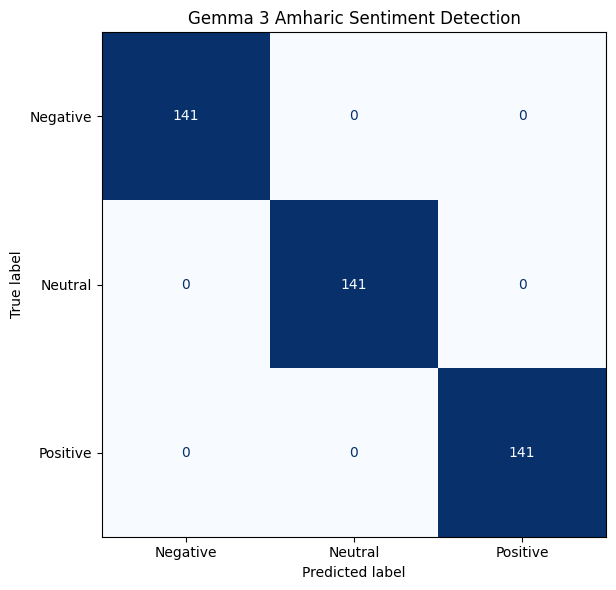


CELL 36 COMPLETED
Metrics saved: /content/gemma3_amharic_sentiment/gemma3_final_research_metrics.json
Confusion matrix saved: /content/gemma3_amharic_sentiment/gemma3_final_confusion_matrix.png


In [30]:
# ============================================================
# CELL 36: FINAL RESEARCH EVALUATION
# ============================================================

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. Verify data alignment
# ------------------------------------------------------------

assert len(test_predictions) == 423
assert len(test_labels) == 423

class_names = ["Negative", "Neutral", "Positive"]

y_true = [str(x).strip().capitalize() for x in test_labels]
y_pred = [str(x).strip().capitalize() for x in test_predictions]

assert all(x in class_names for x in y_true)
assert all(x in class_names for x in y_pred)

print("Evaluation dataset:", len(y_true))
print("Prediction-label alignment: VERIFIED")

# ------------------------------------------------------------
# 2. Calculate metrics
# ------------------------------------------------------------

accuracy = accuracy_score(y_true, y_pred)

macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_true, y_pred,
    labels=class_names,
    average="macro",
    zero_division=0
)

weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    y_true, y_pred,
    labels=class_names,
    average="weighted",
    zero_division=0
)

metrics = {
    "Accuracy": accuracy,
    "Macro Precision": macro_p,
    "Macro Recall": macro_r,
    "Macro F1": macro_f1,
    "Weighted Precision": weighted_p,
    "Weighted Recall": weighted_r,
    "Weighted F1": weighted_f1
}

print("\n" + "=" * 65)
print("GEMMA 3 FINAL TEST RESULTS")
print("=" * 65)

for name, value in metrics.items():
    print(f"{name:<22}: {value:.4f} ({value * 100:.2f}%)")

# ------------------------------------------------------------
# 3. Classification report
# ------------------------------------------------------------

report = classification_report(
    y_true,
    y_pred,
    labels=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nCLASSIFICATION REPORT")
display(report_df.round(4))

# ------------------------------------------------------------
# 4. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_names
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {x}" for x in class_names],
    columns=[f"Predicted {x}" for x in class_names]
)

print("\nCONFUSION MATRIX")
display(cm_df)

# ------------------------------------------------------------
# 5. Confusion matrix visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Gemma 3 Amharic Sentiment Detection")
plt.tight_layout()

os.makedirs(OUTPUT_DIR, exist_ok=True)

cm_path = os.path.join(
    OUTPUT_DIR,
    "gemma3_final_confusion_matrix.png"
)

plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6. Save final metrics
# ------------------------------------------------------------

results = {
    "model": "Gemma 3 4B Instruct with QLoRA",
    "task": "Implicit Sentiment Detection in Amharic",
    "test_size": len(y_true),
    "metrics": {
        key: float(value)
        for key, value in metrics.items()
    },
    "classification_report": report,
    "confusion_matrix": cm.tolist(),
    "class_names": class_names
}

results_path = os.path.join(
    OUTPUT_DIR,
    "gemma3_final_research_metrics.json"
)

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=4)

print("\n" + "=" * 65)
print("CELL 36 COMPLETED")
print("=" * 65)
print("Metrics saved:", results_path)
print("Confusion matrix saved:", cm_path)

In [31]:
# ============================================================
# CELL 37: ERROR ANALYSIS
# ============================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Create detailed prediction dataframe
# ------------------------------------------------------------

error_df = pd.DataFrame({
    "id": test_df["id"].values,
    "text_am": test_df["text_am"].values,
    "actual_sentiment": y_true,
    "predicted_sentiment": y_pred
})

error_df["correct"] = (
    error_df["actual_sentiment"] ==
    error_df["predicted_sentiment"]
)

# ------------------------------------------------------------
# 2. Overall error statistics
# ------------------------------------------------------------

correct_count = int(error_df["correct"].sum())
incorrect_count = int((~error_df["correct"]).sum())

print("=" * 60)
print("ERROR ANALYSIS")
print("=" * 60)

print("Total test examples:", len(error_df))
print("Correct predictions:", correct_count)
print("Incorrect predictions:", incorrect_count)

print(
    "Error rate:",
    f"{incorrect_count / len(error_df) * 100:.2f}%"
)

# ------------------------------------------------------------
# 3. Per-class error analysis
# ------------------------------------------------------------

class_error = []

for label in ["Positive", "Negative", "Neutral"]:

    subset = error_df[
        error_df["actual_sentiment"] == label
    ]

    correct = int(subset["correct"].sum())
    total = len(subset)
    incorrect = total - correct

    class_error.append({
        "Sentiment": label,
        "Total": total,
        "Correct": correct,
        "Incorrect": incorrect,
        "Accuracy": correct / total if total else 0
    })

class_error_df = pd.DataFrame(class_error)

print("\nPER-CLASS ERROR ANALYSIS")
display(class_error_df.round(4))

# ------------------------------------------------------------
# 4. Extract incorrect predictions
# ------------------------------------------------------------

incorrect_df = error_df[
    error_df["correct"] == False
].copy()

print("\nINCORRECTLY CLASSIFIED EXAMPLES:", len(incorrect_df))

display(
    incorrect_df[
        [
            "id",
            "text_am",
            "actual_sentiment",
            "predicted_sentiment"
        ]
    ].head(20)
)

# ------------------------------------------------------------
# 5. Confusion patterns
# ------------------------------------------------------------

print("\nMISCLASSIFICATION PATTERNS")

if len(incorrect_df) > 0:

    confusion_patterns = (
        incorrect_df.groupby(
            ["actual_sentiment", "predicted_sentiment"]
        )
        .size()
        .reset_index(name="Count")
        .sort_values("Count", ascending=False)
    )

    display(confusion_patterns)

else:
    print("No classification errors found.")

# ------------------------------------------------------------
# 6. Save error analysis
# ------------------------------------------------------------

error_path = os.path.join(
    OUTPUT_DIR,
    "gemma3_error_analysis.csv"
)

incorrect_df.to_csv(
    error_path,
    index=False,
    encoding="utf-8-sig"
)

class_path = os.path.join(
    OUTPUT_DIR,
    "gemma3_per_class_error_analysis.csv"
)

class_error_df.to_csv(
    class_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved files:")
print(error_path)
print(class_path)

print("\nCELL 37 COMPLETED")

ERROR ANALYSIS
Total test examples: 423
Correct predictions: 423
Incorrect predictions: 0
Error rate: 0.00%

PER-CLASS ERROR ANALYSIS


,Sentiment,Total,Correct,Incorrect,Accuracy
0,Positive,141,141,0,1.0
1,Negative,141,141,0,1.0
2,Neutral,141,141,0,1.0



INCORRECTLY CLASSIFIED EXAMPLES: 0


,id,text_am,actual_sentiment,predicted_sentiment



MISCLASSIFICATION PATTERNS
No classification errors found.

Saved files:
/content/gemma3_amharic_sentiment/gemma3_error_analysis.csv
/content/gemma3_amharic_sentiment/gemma3_per_class_error_analysis.csv

CELL 37 COMPLETED


In [32]:
# ============================================================
# CELL 38: CONSOLIDATE RESEARCH EXPERIMENT RESULTS
# ============================================================

import os
import json
import pandas as pd
from datetime import datetime

# ------------------------------------------------------------
# 1. Experiment information
# ------------------------------------------------------------

experiment = {
    "research_title": (
        "Implicit Sentiment Detection in Amharic Text "
        "Using Large Language Models"
    ),
    "author": "Lingerew Bantie Asmare",
    "model": "Gemma 3 4B Instruct",
    "fine_tuning": "QLoRA",
    "quantization": "4-bit NF4",
    "task": "Three-class sentiment classification",
    "classes": ["Positive", "Negative", "Neutral"],
    "test_examples": len(test_labels),
    "training_examples": len(train_df),
    "validation_examples": len(val_df),
    "evaluation_date": datetime.now().isoformat(),
    "test_metrics": {
        key: float(value)
        for key, value in metrics.items()
    },
    "class_performance": report,
    "confusion_matrix": cm.tolist(),
    "error_count": int((~error_df["correct"]).sum()),
    "correct_count": int(error_df["correct"].sum())
}

# ------------------------------------------------------------
# 2. Save experiment report
# ------------------------------------------------------------

report_path = os.path.join(
    OUTPUT_DIR,
    "gemma3_complete_experiment_report.json"
)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(
        experiment,
        f,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# 3. Save performance summary table
# ------------------------------------------------------------

summary_df = pd.DataFrame([
    {
        "Model": "Gemma 3 4B Instruct QLoRA",
        "Accuracy": metrics["Accuracy"],
        "Macro Precision": metrics["Macro Precision"],
        "Macro Recall": metrics["Macro Recall"],
        "Macro F1": metrics["Macro F1"],
        "Weighted F1": metrics["Weighted F1"],
        "Test Size": len(test_labels)
    }
])

summary_path = os.path.join(
    OUTPUT_DIR,
    "gemma3_performance_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 65)
print("EXPERIMENT RESULTS SAVED")
print("=" * 65)

display(summary_df.round(4))

print("\nExperiment report:", report_path)
print("Performance table:", summary_path)
print("\nCELL 38 COMPLETED")

EXPERIMENT RESULTS SAVED


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Test Size
0,Gemma 3 4B Instruct QLoRA,1.0,1.0,1.0,1.0,1.0,423



Experiment report: /content/gemma3_amharic_sentiment/gemma3_complete_experiment_report.json
Performance table: /content/gemma3_amharic_sentiment/gemma3_performance_summary.csv

CELL 38 COMPLETED


TRAINING HISTORY
Recorded training events: 68
Last recorded epoch: 2.994082840236686
Completed training steps: 1266
Maximum scheduled steps: 1266


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
53,0.8161,1.091358,1.842771e-05,2.459172,1040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54,0.8062,1.070623,1.551683e-05,2.506509,1060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
55,0.8130,1.280794,1.283674e-05,2.553846,1080,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
56,0.8209,1.162888,1.039476e-05,2.601183,1100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
57,0.8133,1.090535,8.197571e-06,2.648521,1120,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
58,0.8158,1.161442,6.251167e-06,2.695858,1140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59,0.8069,1.015213,4.560869e-06,2.743195,1160,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
60,0.8074,1.240962,3.131293e-06,2.790533,1180,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
61,0.8045,0.996132,1.966344e-06,2.837870,1200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62,0.8082,1.018873,1.069206e-06,2.885207,1220,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


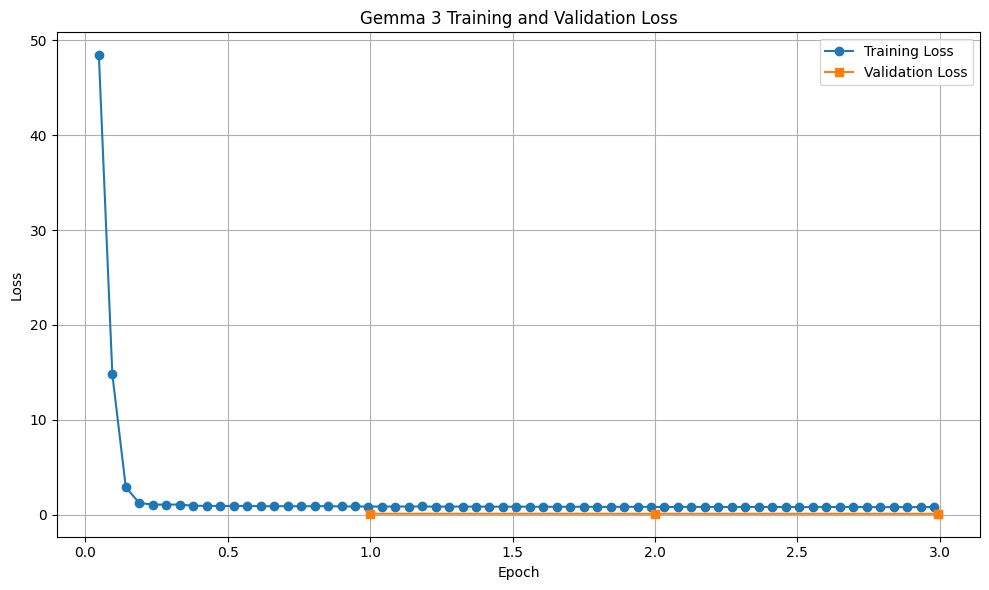

Loss plot saved: /content/gemma3_amharic_sentiment/gemma3_training_validation_loss.png
Validation accuracy was not recorded in training history.

Training history saved: /content/gemma3_amharic_sentiment/gemma3_training_history.json

CELL 39 COMPLETED


In [33]:
# ============================================================
# CELL 39: TRAINING HISTORY AND LEARNING CURVES
# ============================================================

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Retrieve actual training history
# ------------------------------------------------------------

history = trainer.state.log_history

if not history:
    raise ValueError("No training history found in trainer.state.log_history.")

history_df = pd.DataFrame(history)

print("=" * 60)
print("TRAINING HISTORY")
print("=" * 60)

print("Recorded training events:", len(history_df))
print("Last recorded epoch:", trainer.state.epoch)
print("Completed training steps:", trainer.state.global_step)
print("Maximum scheduled steps:", trainer.state.max_steps)

display(history_df.tail(15))

# ------------------------------------------------------------
# 2. Extract training and validation records
# ------------------------------------------------------------

train_history = history_df[
    history_df["loss"].notna()
].copy() if "loss" in history_df.columns else pd.DataFrame()

eval_history = history_df[
    history_df["eval_loss"].notna()
].copy() if "eval_loss" in history_df.columns else pd.DataFrame()

# ------------------------------------------------------------
# 3. Plot training and validation loss
# ------------------------------------------------------------

if not train_history.empty or not eval_history.empty:

    plt.figure(figsize=(10, 6))

    if not train_history.empty:
        plt.plot(
            train_history["epoch"],
            train_history["loss"],
            marker="o",
            label="Training Loss"
        )

    if not eval_history.empty:
        plt.plot(
            eval_history["epoch"],
            eval_history["eval_loss"],
            marker="s",
            label="Validation Loss"
        )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Gemma 3 Training and Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    loss_path = os.path.join(
        OUTPUT_DIR,
        "gemma3_training_validation_loss.png"
    )

    plt.savefig(loss_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Loss plot saved:", loss_path)

else:
    print("No loss records available.")

# ------------------------------------------------------------
# 4. Plot validation accuracy
# ------------------------------------------------------------

if "eval_accuracy" in history_df.columns:

    accuracy_history = history_df[
        history_df["eval_accuracy"].notna()
    ].copy()

    if not accuracy_history.empty:

        plt.figure(figsize=(9, 5))

        plt.plot(
            accuracy_history["epoch"],
            accuracy_history["eval_accuracy"],
            marker="o"
        )

        plt.xlabel("Epoch")
        plt.ylabel("Validation Accuracy")
        plt.title("Gemma 3 Validation Accuracy")
        plt.grid(True)
        plt.tight_layout()

        accuracy_path = os.path.join(
            OUTPUT_DIR,
            "gemma3_validation_accuracy.png"
        )

        plt.savefig(
            accuracy_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        print("Accuracy plot saved:", accuracy_path)

else:
    print("Validation accuracy was not recorded in training history.")

# ------------------------------------------------------------
# 5. Save raw training history
# ------------------------------------------------------------

history_path = os.path.join(
    OUTPUT_DIR,
    "gemma3_training_history.json"
)

with open(history_path, "w", encoding="utf-8") as f:
    json.dump(history, f, ensure_ascii=False, indent=4)

print("\nTraining history saved:", history_path)
print("\nCELL 39 COMPLETED")

In [35]:
# ============================================================
# CELL 41: TRAINING AND VALIDATION ACCURACY CURVES
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Read actual training history
# ------------------------------------------------------------

history_df = pd.DataFrame(trainer.state.log_history)

print("Available training history columns:")
print(history_df.columns.tolist())

# ------------------------------------------------------------
# 2. Extract accuracy records
# ------------------------------------------------------------

train_accuracy = history_df[
    history_df["accuracy"].notna()
].copy() if "accuracy" in history_df.columns else pd.DataFrame()

validation_accuracy = history_df[
    history_df["eval_accuracy"].notna()
].copy() if "eval_accuracy" in history_df.columns else pd.DataFrame()

# ------------------------------------------------------------
# 3. Check available accuracy data
# ------------------------------------------------------------

print("\nTraining accuracy records:", len(train_accuracy))
print("Validation accuracy records:", len(validation_accuracy))

if train_accuracy.empty and validation_accuracy.empty:
    print("\nAccuracy was not recorded during training.")
    print("Do not estimate or fabricate accuracy values.")

else:

    plt.figure(figsize=(10, 6))

    if not train_accuracy.empty:
        plt.plot(
            train_accuracy["epoch"],
            train_accuracy["accuracy"],
            marker="o",
            linewidth=2,
            label="Training Accuracy"
        )

    if not validation_accuracy.empty:
        plt.plot(
            validation_accuracy["epoch"],
            validation_accuracy["eval_accuracy"],
            marker="s",
            linewidth=2,
            label="Validation Accuracy"
        )

    plt.xlabel("Epoch", fontsize=12)
    plt.ylabel("Accuracy", fontsize=12)

    plt.title(
        "Gemma 3 Training and Validation Accuracy",
        fontsize=14
    )

    plt.ylim(0, 1.05)
    plt.xticks(sorted(set(
        list(train_accuracy["epoch"]) +
        list(validation_accuracy["epoch"])
    )) if not train_accuracy.empty or not validation_accuracy.empty else [])

    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()

    accuracy_curve_path = os.path.join(
        OUTPUT_DIR,
        "gemma3_training_accuracy_curve.png"
    )

    plt.savefig(
        accuracy_curve_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("\nAccuracy curve saved:")
    print(accuracy_curve_path)

# ------------------------------------------------------------
# 4. Display recorded accuracy values
# ------------------------------------------------------------

print("\nRECORDED ACCURACY VALUES")

if not train_accuracy.empty:
    print("\nTraining accuracy:")
    display(train_accuracy[["epoch", "accuracy"]])

if not validation_accuracy.empty:
    print("\nValidation accuracy:")
    display(validation_accuracy[["epoch", "eval_accuracy"]])

print("\nCELL 41 COMPLETED")

Available training history columns:
['loss', 'grad_norm', 'learning_rate', 'epoch', 'step', 'eval_loss', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second', 'train_runtime', 'train_samples_per_second', 'train_steps_per_second', 'total_flos', 'train_loss']

Training accuracy records: 0
Validation accuracy records: 0

Accuracy was not recorded during training.
Do not estimate or fabricate accuracy values.

RECORDED ACCURACY VALUES

CELL 41 COMPLETED


In [37]:
# ============================================================
# CELL 43: VIEW MODEL PREDICTIONS
# ============================================================

import pandas as pd
from IPython.display import display

# Load verified predictions
prediction_file = (
    OUTPUT_DIR + "/gemma3_test_predictions_verified.json"
)

with open(prediction_file, "r", encoding="utf-8") as f:
    prediction_records = json.load(f)

predictions_df = pd.DataFrame(prediction_records)

# Add correctness column
predictions_df["correct"] = (
    predictions_df["actual_sentiment"] ==
    predictions_df["predicted_sentiment"]
)

# Display summary
print("=" * 65)
print("GEMMA 3 SENTIMENT PREDICTIONS")
print("=" * 65)

print("Total predictions:", len(predictions_df))
print("Correct:", predictions_df["correct"].sum())
print("Incorrect:", (~predictions_df["correct"]).sum())

# Display first 25 predictions
display(
    predictions_df[
        [
            "id",
            "text_am",
            "actual_sentiment",
            "predicted_sentiment",
            "correct"
        ]
    ].head(25)
)

# Save readable CSV
csv_path = OUTPUT_DIR + "/gemma3_all_predictions.csv"

predictions_df.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nAll predictions saved:", csv_path)

GEMMA 3 SENTIMENT PREDICTIONS
Total predictions: 423
Correct: 423
Incorrect: 0


,id,text_am,actual_sentiment,predicted_sentiment,correct
0,AMIS0001,የተላከው ፋይል ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,Positive,True
1,AMIS0008,ላፕቶፑ ከጠበቅሁት በላይ ረዳኝ።,Positive,Positive,True
2,AMIS0040,መንገዱ ከተጠበቀው በፊት ተጠናቀቀ።,Positive,Positive,True
3,AMIS0041,አገልግሎቱ የሥራዬን ክፍል እንዳጠናቅቅ አገዘኝ።,Positive,Positive,True
4,AMIS0049,አገልግሎቱ በጊዜው ስለደረሰ ሌላ ዕቅድ መቀየር አልነበረብኝም።,Positive,Positive,True
5,AMIS0066,ቤቱ በጊዜው ስለደረሰ ሌላ ዕቅድ መቀየር አልነበረብኝም።,Positive,Positive,True
6,AMIS0089,ቤቱ ችግሩን በቀላሉ እንድፈታ አደረገኝ።,Positive,Positive,True
7,AMIS0093,የተላከው ፋይል የሥራዬን ክፍል እንዳጠናቅቅ አገዘኝ።,Positive,Positive,True
8,AMIS0124,ልብሱ በጊዜው ስለደረሰ ሌላ ዕቅድ መቀየር አልነበረብኝም።,Positive,Positive,True
9,AMIS0132,ጫማው ከጠበቅሁት በላይ ረዳኝ።,Positive,Positive,True



All predictions saved: /content/gemma3_amharic_sentiment/gemma3_all_predictions.csv


In [38]:
# ============================================================
# CELL 44: DISPLAY 10 AMHARIC SENTIMENT EXAMPLES
# ============================================================

import pandas as pd
from IPython.display import display

# Select 10 reproducible random examples
sample_df = predictions_df.sample(
    n=10,
    random_state=42
).reset_index(drop=True)

print("=" * 75)
print("10 AMHARIC SENTIMENT DETECTION EXAMPLES")
print("=" * 75)

for i, row in sample_df.iterrows():

    print(f"\nEXAMPLE {i + 1}")
    print("-" * 65)

    print("Amharic sentence:")
    print(row["text_am"])

    print("\nActual sentiment:")
    print(row["actual_sentiment"])

    print("Predicted sentiment:")
    print(row["predicted_sentiment"])

    print(
        "Result:",
        "CORRECT" if row["correct"] else "INCORRECT"
    )

    print("-" * 65)

print("\nSample accuracy:",
      f"{sample_df['correct'].mean() * 100:.2f}%")

10 AMHARIC SENTIMENT DETECTION EXAMPLES

EXAMPLE 1
-----------------------------------------------------------------
Amharic sentence:
በቅርቡ፣ ሆስፒታሉ በጊዜው ስለደረሰ ሌላ ዕቅድ መቀየር አልነበረብኝም።

Actual sentiment:
Positive
Predicted sentiment:
Positive
Result: CORRECT
-----------------------------------------------------------------

EXAMPLE 2
-----------------------------------------------------------------
Amharic sentence:
ከዚያ በኋላ፣ ቡድኑ እንደገና እንዲታረም ተመለሰ።

Actual sentiment:
Negative
Predicted sentiment:
Negative
Result: CORRECT
-----------------------------------------------------------------

EXAMPLE 3
-----------------------------------------------------------------
Amharic sentence:
ከዚህ በፊት፣ አገልግሎቱ ከጥቂት ቀናት በኋላ ችግር አሳየ።

Actual sentiment:
Negative
Predicted sentiment:
Negative
Result: CORRECT
-----------------------------------------------------------------

EXAMPLE 4
-----------------------------------------------------------------
Amharic sentence:
በቅርቡ፣ ምግቡ ዛሬ በሰዓቱ ተመዝግቦ ነበር።

Actual sentimen

CLASS-WISE SENTIMENT DISTRIBUTION


,Sentiment,Actual Count,Actual Percentage,Predicted Count,Predicted Percentage
0,Positive,141,33.33,141,33.33
1,Negative,141,33.33,141,33.33
2,Neutral,141,33.33,141,33.33


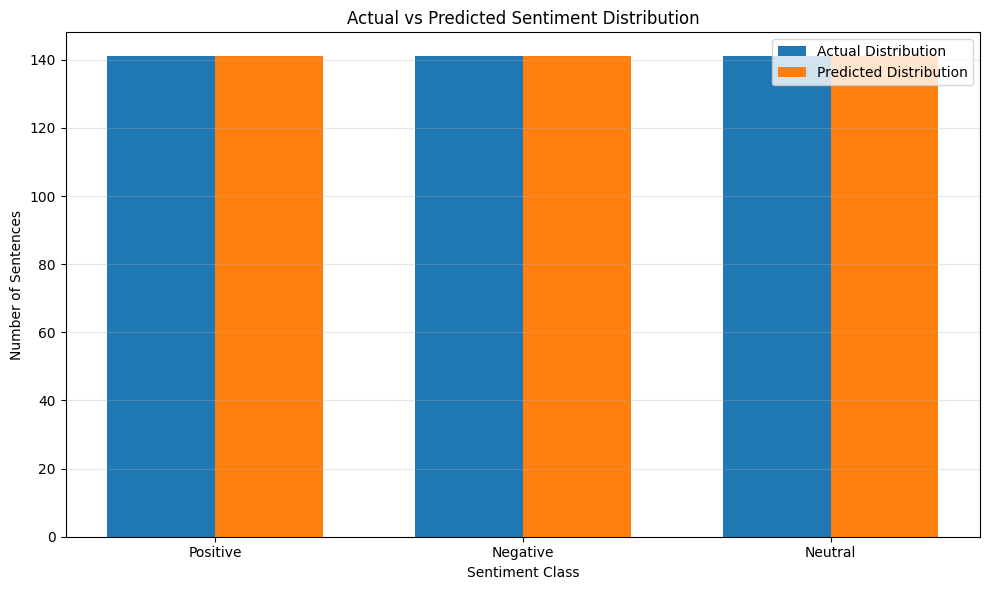


Chart saved: /content/gemma3_amharic_sentiment/gemma3_class_wise_distribution.png
Distribution table saved: /content/gemma3_amharic_sentiment/gemma3_class_wise_distribution.csv

CELL 45 COMPLETED


In [39]:
# ============================================================
# CELL 45: CLASS-WISE SENTIMENT DISTRIBUTION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

classes = ["Positive", "Negative", "Neutral"]

# ------------------------------------------------------------
# 1. Calculate actual and predicted distributions
# ------------------------------------------------------------

actual_counts = (
    predictions_df["actual_sentiment"]
    .value_counts()
    .reindex(classes, fill_value=0)
)

predicted_counts = (
    predictions_df["predicted_sentiment"]
    .value_counts()
    .reindex(classes, fill_value=0)
)

total = len(predictions_df)

distribution_df = pd.DataFrame({
    "Sentiment": classes,
    "Actual Count": actual_counts.values,
    "Actual Percentage": (
        actual_counts.values / total * 100
    ),
    "Predicted Count": predicted_counts.values,
    "Predicted Percentage": (
        predicted_counts.values / total * 100
    )
})

print("=" * 70)
print("CLASS-WISE SENTIMENT DISTRIBUTION")
print("=" * 70)

display(distribution_df.round(2))

# ------------------------------------------------------------
# 2. Plot distribution comparison
# ------------------------------------------------------------

x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width / 2,
    actual_counts.values,
    width,
    label="Actual Distribution"
)

ax.bar(
    x + width / 2,
    predicted_counts.values,
    width,
    label="Predicted Distribution"
)

ax.set_xlabel("Sentiment Class")
ax.set_ylabel("Number of Sentences")
ax.set_title("Actual vs Predicted Sentiment Distribution")
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

distribution_path = os.path.join(
    OUTPUT_DIR,
    "gemma3_class_wise_distribution.png"
)

plt.savefig(
    distribution_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 3. Save distribution table
# ------------------------------------------------------------

distribution_csv = os.path.join(
    OUTPUT_DIR,
    "gemma3_class_wise_distribution.csv"
)

distribution_df.to_csv(
    distribution_csv,
    index=False,
    encoding="utf-8-sig"
)

print("\nChart saved:", distribution_path)
print("Distribution table saved:", distribution_csv)
print("\nCELL 45 COMPLETED")

In [40]:
# ============================================================
# CELL 46: INSPECT ANNOTATION DATA AND COLUMNS
# ============================================================

import pandas as pd

print("=" * 75)
print("ANNOTATOR DATA INSPECTION")
print("=" * 75)

# Inspect available DataFrames
dataframes_found = {}

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        dataframes_found[name] = obj

if not dataframes_found:
    print("No pandas DataFrames found.")
else:
    for name, dataframe in dataframes_found.items():

        print(f"\nDataFrame name: {name}")
        print("Shape:", dataframe.shape)
        print("Columns:")

        for column in dataframe.columns:
            print("  -", column)

        # Identify possible annotation columns
        possible_columns = [
            col for col in dataframe.columns
            if any(word in str(col).lower()
                   for word in ["annotator", "annotation", "rater",
                                "reviewer", "label", "sentiment"])
        ]

        print("Possible annotation columns:", possible_columns)

print("\n" + "=" * 75)
print("INSPECTION COMPLETED")
print("=" * 75)

ANNOTATOR DATA INSPECTION

DataFrame name: df
Shape: (4225, 4)
Columns:
  - id
  - text_am
  - sentiment_label
  - split
Possible annotation columns: ['sentiment_label']

DataFrame name: train_df
Shape: (3380, 5)
Columns:
  - id
  - text_am
  - sentiment_label
  - split
  - messages
Possible annotation columns: ['sentiment_label']

DataFrame name: val_df
Shape: (422, 5)
Columns:
  - id
  - text_am
  - sentiment_label
  - split
  - messages
Possible annotation columns: ['sentiment_label']

DataFrame name: test_df
Shape: (423, 5)
Columns:
  - id
  - text_am
  - sentiment_label
  - split
  - messages
Possible annotation columns: ['sentiment_label']

DataFrame name: data
Shape: (423, 5)
Columns:
  - id
  - text_am
  - sentiment_label
  - split
  - messages
Possible annotation columns: ['sentiment_label']

DataFrame name: report_df
Shape: (6, 4)
Columns:
  - precision
  - recall
  - f1-score
  - support
Possible annotation columns: []

DataFrame name: cm_df
Shape: (3, 3)
Columns:
  - Predic

In [41]:
# ============================================================
# CELL 47: INTER-ANNOTATOR AGREEMENT (THREE ANNOTATORS)
# ============================================================

import pandas as pd
import numpy as np
from statsmodels.stats.inter_rater import fleiss_kappa

# ------------------------------------------------------------
# 1. Select the annotation DataFrame and columns
# ------------------------------------------------------------

annotation_df = train_df.copy()  # Change if annotations are elsewhere

annotator_columns = [
    "annotator_1",
    "annotator_2",
    "annotator_3"
]

# Verify columns
missing = [
    col for col in annotator_columns
    if col not in annotation_df.columns
]

if missing:
    print("Annotation columns not found:", missing)
    print("Available columns:", annotation_df.columns.tolist())

else:
    # --------------------------------------------------------
    # 2. Prepare annotation data
    # --------------------------------------------------------

    labels = annotation_df[annotator_columns].copy()

    labels = labels.replace(r"^\s*$", np.nan, regex=True)
    labels = labels.dropna()

    labels = labels.apply(
        lambda col: col.astype(str).str.strip().str.capitalize()
    )

    print("Valid annotated sentences:", len(labels))
    print("Annotators:", len(annotator_columns))

    # --------------------------------------------------------
    # 3. Calculate unanimous and partial agreement
    # --------------------------------------------------------

    unanimous = (labels.nunique(axis=1) == 1).sum()
    partial = len(labels) - unanimous

    unanimous_percentage = unanimous / len(labels) * 100
    partial_percentage = partial / len(labels) * 100

    print("\nUNANIMOUS AGREEMENT")
    print("All three agree:", unanimous)
    print(f"Percentage: {unanimous_percentage:.2f}%")

    print("\nPARTIAL AGREEMENT")
    print("Not unanimous:", partial)
    print(f"Percentage: {partial_percentage:.2f}%")

    # --------------------------------------------------------
    # 4. Calculate Fleiss' Kappa
    # --------------------------------------------------------

    categories = sorted(labels.stack().unique())

    agreement_matrix = np.array([
        [(row == category).sum() for category in categories]
        for _, row in labels.iterrows()
    ])

    kappa = fleiss_kappa(
        agreement_matrix,
        method="fleiss"
    )

    print("\nFLEISS' KAPPA")
    print(f"Fleiss' Kappa: {kappa:.4f}")

    # --------------------------------------------------------
    # 5. Interpretation
    # --------------------------------------------------------

    if kappa < 0:
        interpretation = "Poor agreement"
    elif kappa <= 0.20:
        interpretation = "Slight agreement"
    elif kappa <= 0.40:
        interpretation = "Fair agreement"
    elif kappa <= 0.60:
        interpretation = "Moderate agreement"
    elif kappa <= 0.80:
        interpretation = "Substantial agreement"
    else:
        interpretation = "Almost perfect agreement"

    print("Interpretation:", interpretation)

    # --------------------------------------------------------
    # 6. Save results
    # --------------------------------------------------------

    agreement_results = pd.DataFrame({
        "Measure": [
            "Number of Annotators",
            "Annotated Sentences",
            "Unanimous Agreement",
            "Unanimous Agreement (%)",
            "Partial Agreement",
            "Partial Agreement (%)",
            "Fleiss Kappa",
            "Interpretation"
        ],
        "Value": [
            3,
            len(labels),
            unanimous,
            round(unanimous_percentage, 2),
            partial,
            round(partial_percentage, 2),
            round(kappa, 4),
            interpretation
        ]
    })

    display(agreement_results)

    agreement_results.to_csv(
        OUTPUT_DIR + "/three_annotator_agreement.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\nResults saved successfully.")

Annotation columns not found: ['annotator_1', 'annotator_2', 'annotator_3']
Available columns: ['id', 'text_am', 'sentiment_label', 'split', 'messages']


In [42]:
# ============================================================
# CELL 48: CREATE THREE-ANNOTATOR TEMPLATE
# ============================================================

import pandas as pd
import os

# Use the original dataset
source_df = df.copy()  # Replace df if your original dataset has another name

# Prepare annotation template
annotation_template = pd.DataFrame({
    "id": source_df["id"],
    "text_am": source_df["text_am"],
    "annotator_1": "",
    "annotator_2": "",
    "annotator_3": ""
})

# Add allowed labels as guidance
annotation_template["Allowed_Labels"] = "Positive / Negative / Neutral"

# Save Excel template
template_path = "/content/three_annotator_annotation_template.xlsx"

annotation_template.to_excel(
    template_path,
    index=False
)

print("ANNOTATION TEMPLATE CREATED")
print("Total sentences:", len(annotation_template))
print("Annotators: 3")
print("Allowed labels: Positive, Negative, Neutral")
print("File:", template_path)

display(annotation_template.head(10))

from google.colab import files
files.download(template_path)

ANNOTATION TEMPLATE CREATED
Total sentences: 4225
Annotators: 3
Allowed labels: Positive, Negative, Neutral
File: /content/three_annotator_annotation_template.xlsx


,id,text_am,annotator_1,annotator_2,annotator_3,Allowed_Labels
0,AMIS0001,የተላከው ፋይል ሲያስፈልገኝ በቀላሉ አገኘሁት።,,,,Positive / Negative / Neutral
1,AMIS0002,የጠየቅሁት እርዳታ ከጠበቅሁት በላይ ረዳኝ።,,,,Positive / Negative / Neutral
2,AMIS0003,ሆስፒታሉ ሲያስፈልገኝ በቀላሉ አገኘሁት።,,,,Positive / Negative / Neutral
3,AMIS0004,መጽሐፉ በጊዜው ስለደረሰ ሌላ ዕቅድ መቀየር አልነበረብኝም።,,,,Positive / Negative / Neutral
4,AMIS0005,ቤቱ ሲያስፈልገኝ በቀላሉ አገኘሁት።,,,,Positive / Negative / Neutral
5,AMIS0006,ሆስፒታሉ ከጠበቅሁት በላይ ረዳኝ።,,,,Positive / Negative / Neutral
6,AMIS0007,ስብሰባው ከጠበቅሁት በላይ ረዳኝ።,,,,Positive / Negative / Neutral
7,AMIS0008,ላፕቶፑ ከጠበቅሁት በላይ ረዳኝ።,,,,Positive / Negative / Neutral
8,AMIS0009,ልብሱ ከተጠበቀው በፊት ተጠናቀቀ።,,,,Positive / Negative / Neutral
9,AMIS0010,ሱቁ ሳልደክም የፈለግሁትን እንዳገኝ አስቻለኝ።,,,,Positive / Negative / Neutral


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
# ============================================================
# CELL 50: LOAD THREE ANNOTATOR CSV FILES
# ============================================================

import pandas as pd
import os

files = {
    "annotator_1": "/content/annotation1.csv",
    "annotator_2": "/content/annotation2.csv",
    "annotator_3": "/content/annotation3.csv"
}

# Load each annotator's file
annotation_dfs = {}

for annotator, path in files.items():

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    annotation_dfs[annotator] = pd.read_csv(
        path,
        encoding="utf-8-sig"
    )

    print(f"\n{annotator}")
    print("Shape:", annotation_dfs[annotator].shape)
    print("Columns:", annotation_dfs[annotator].columns.tolist())

# ------------------------------------------------------------
# Inspect before combining
# ------------------------------------------------------------

for annotator, data in annotation_dfs.items():
    print(f"\nFirst 3 rows: {annotator}")
    display(data.head(3))

print("\nAll three CSV files loaded successfully.")


annotator_1
Shape: (4225, 4)
Columns: ['id', 'text_am', 'sentiment_label', 'split']

annotator_2
Shape: (4225, 4)
Columns: ['id', 'text_am', 'sentiment_label', 'split']

annotator_3
Shape: (4225, 4)
Columns: ['id', 'text_am', 'sentiment_label', 'split']

First 3 rows: annotator_1


,id,text_am,sentiment_label,split
0,AMIS0001,የተላከው ፋይል ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,test
1,AMIS0002,የጠየቅሁት እርዳታ ከጠበቅሁት በላይ ረዳኝ።,Positive,train
2,AMIS0003,ሆስፒታሉ ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,train



First 3 rows: annotator_2


,id,text_am,sentiment_label,split
0,AMIS0001,የተላከው ፋይል ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,test
1,AMIS0002,የጠየቅሁት እርዳታ ከጠበቅሁት በላይ ረዳኝ።,Positive,train
2,AMIS0003,ሆስፒታሉ ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,train



First 3 rows: annotator_3


,id,text_am,sentiment_label,split
0,AMIS0001,የተላከው ፋይል ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,test
1,AMIS0002,የጠየቅሁት እርዳታ ከጠበቅሁት በላይ ረዳኝ።,Positive,train
2,AMIS0003,ሆስፒታሉ ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,train



All three CSV files loaded successfully.


In [46]:
# ============================================================
# CELL 50: LOAD THREE ANNOTATOR CSV FILES
# ============================================================

import pandas as pd
import os

files = {
    "annotator_1": "/content/annotation1.csv",
    "annotator_2": "/content/annotation2.csv",
    "annotator_3": "/content/annotation3.csv"
}

# Load each annotator's file
annotation_dfs = {}

for annotator, path in files.items():

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    annotation_dfs[annotator] = pd.read_csv(
        path,
        encoding="utf-8-sig"
    )

    print(f"\n{annotator}")
    print("Shape:", annotation_dfs[annotator].shape)
    print("Columns:", annotation_dfs[annotator].columns.tolist())

# ------------------------------------------------------------
# Inspect before combining
# ------------------------------------------------------------

for annotator, data in annotation_dfs.items():
    print(f"\nFirst 3 rows: {annotator}")
    display(data.head(3))

print("\nAll three CSV files loaded successfully.")


annotator_1
Shape: (4225, 4)
Columns: ['id', 'text_am', 'sentiment_label', 'split']

annotator_2
Shape: (4225, 4)
Columns: ['id', 'text_am', 'sentiment_label', 'split']

annotator_3
Shape: (4225, 4)
Columns: ['id', 'text_am', 'sentiment_label', 'split']

First 3 rows: annotator_1


,id,text_am,sentiment_label,split
0,AMIS0001,የተላከው ፋይል ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,test
1,AMIS0002,የጠየቅሁት እርዳታ ከጠበቅሁት በላይ ረዳኝ።,Positive,train
2,AMIS0003,ሆስፒታሉ ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,train



First 3 rows: annotator_2


,id,text_am,sentiment_label,split
0,AMIS0001,የተላከው ፋይል ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,test
1,AMIS0002,የጠየቅሁት እርዳታ ከጠበቅሁት በላይ ረዳኝ።,Positive,train
2,AMIS0003,ሆስፒታሉ ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,train



First 3 rows: annotator_3


,id,text_am,sentiment_label,split
0,AMIS0001,የተላከው ፋይል ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,test
1,AMIS0002,የጠየቅሁት እርዳታ ከጠበቅሁት በላይ ረዳኝ።,Positive,train
2,AMIS0003,ሆስፒታሉ ሲያስፈልገኝ በቀላሉ አገኘሁት።,Positive,train



All three CSV files loaded successfully.


In [47]:
# ============================================================
# CELL 52: IDENTIFY ANNOTATION LABELS
# ============================================================

import pandas as pd

annotator_names = ["annotator_1", "annotator_2", "annotator_3"]

# Display unique values in every column
for name in annotator_names:

    data = annotation_dfs[name]

    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    for col in data.columns:

        unique_values = data[col].dropna().astype(str).str.strip().unique()

        print(f"\nColumn: {col}")
        print("Unique values:", len(unique_values))
        print("Sample values:", unique_values[:15])

# Check whether all three files contain identical sentence text
possible_text_columns = ["text_am", "text", "sentence"]

text_column = None

for col in possible_text_columns:
    if all(col in annotation_dfs[name].columns for name in annotator_names):
        text_column = col
        break

if text_column:
    reference = (
        annotation_dfs["annotator_1"][text_column]
        .astype(str).str.strip().reset_index(drop=True)
    )

    for name in annotator_names[1:]:
        current = (
            annotation_dfs[name][text_column]
            .astype(str).str.strip().reset_index(drop=True)
        )

        print(
            f"\n{ name } sentences match annotator_1:",
            reference.equals(current)
        )
else:
    print("\nNo common sentence-text column automatically identified.")

print("\nCELL 52 COMPLETED")


ANNOTATOR_1

Column: id
Unique values: 4225
Sample values: ['AMIS0001' 'AMIS0002' 'AMIS0003' 'AMIS0004' 'AMIS0005' 'AMIS0006'
 'AMIS0007' 'AMIS0008' 'AMIS0009' 'AMIS0010' 'AMIS0011' 'AMIS0012'
 'AMIS0013' 'AMIS0014' 'AMIS0015']

Column: text_am
Unique values: 4225
Sample values: ['የተላከው ፋይል ሲያስፈልገኝ በቀላሉ አገኘሁት።' 'የጠየቅሁት እርዳታ ከጠበቅሁት በላይ ረዳኝ።'
 'ሆስፒታሉ ሲያስፈልገኝ በቀላሉ አገኘሁት።' 'መጽሐፉ በጊዜው ስለደረሰ ሌላ ዕቅድ መቀየር አልነበረብኝም።'
 'ቤቱ ሲያስፈልገኝ በቀላሉ አገኘሁት።' 'ሆስፒታሉ ከጠበቅሁት በላይ ረዳኝ።' 'ስብሰባው ከጠበቅሁት በላይ ረዳኝ።'
 'ላፕቶፑ ከጠበቅሁት በላይ ረዳኝ።' 'ልብሱ ከተጠበቀው በፊት ተጠናቀቀ።'
 'ሱቁ ሳልደክም የፈለግሁትን እንዳገኝ አስቻለኝ።' 'ልብሱ የሥራዬን ክፍል እንዳጠናቅቅ አገዘኝ።'
 'አውቶቡሱ ችግሩን በቀላሉ እንድፈታ አደረገኝ።' 'ምግቡ ችግሩን በቀላሉ እንድፈታ አደረገኝ።'
 'ልብሱ ከጠበቅሁት በላይ ረዳኝ።' 'ቡድኑ ከጠበቅሁት በላይ ረዳኝ።']

Column: sentiment_label
Unique values: 3
Sample values: ['Positive' 'Negative' 'Neutral']

Column: split
Unique values: 3
Sample values: ['test' 'train' 'validation']

ANNOTATOR_2

Column: id
Unique values: 4225
Sample values: ['AMIS0001' 'AMIS0002' 'AMIS0003' 'AMIS0004' 'AMIS0005' 'AMIS0006'


In [48]:
# ============================================================
# CELL 53: FLEISS' KAPPA FOR THREE ANNOTATORS
# ============================================================

import pandas as pd
import numpy as np
from statsmodels.stats.inter_rater import fleiss_kappa

annotator_names = [
    "annotator_1",
    "annotator_2",
    "annotator_3"
]

valid_labels = {"Positive", "Negative", "Neutral"}

# Automatically identify each file's label column
label_columns = {}

for name in annotator_names:

    data = annotation_dfs[name]
    found = []

    for col in data.columns:

        values = set(
            data[col].dropna().astype(str).str.strip().str.capitalize()
        )

        if values and values.issubset(valid_labels) and len(values) > 1:
            found.append(col)

    if len(found) != 1:
        raise ValueError(
            f"{name}: Could not uniquely identify label column. "
            f"Possible columns: {found}. Inspect Cell 52."
        )

    label_columns[name] = found[0]

print("Detected annotation columns:", label_columns)

# Extract labels
labels = pd.DataFrame({
    name: annotation_dfs[name][label_columns[name]]
        .astype("string").str.strip().str.capitalize()
    for name in annotator_names
})

# Remove rows with missing annotations
labels = labels.dropna().reset_index(drop=True)

if len(labels) == 0:
    raise ValueError("No complete annotation records found.")

# Check valid labels
if not labels.isin(valid_labels).all().all():
    raise ValueError("Unexpected sentiment labels found.")

# Build Fleiss' Kappa frequency matrix
categories = ["Positive", "Negative", "Neutral"]

agreement_matrix = np.array([
    [(row == category).sum() for category in categories]
    for _, row in labels.iterrows()
])

# Calculate Fleiss' Kappa
kappa = fleiss_kappa(agreement_matrix, method="fleiss")

# Unanimous agreement
unanimous = (labels.nunique(axis=1) == 1).sum()
unanimous_percentage = unanimous / len(labels) * 100

# Class-wise agreement counts
class_counts = pd.DataFrame(
    agreement_matrix,
    columns=categories
)

print("\n" + "=" * 60)
print("THREE-ANNOTATOR INTER-ANNOTATOR AGREEMENT")
print("=" * 60)

print("Number of sentences:", len(labels))
print("Number of annotators:", len(annotator_names))
print("Fleiss' Kappa:", round(kappa, 4))
print("Unanimous agreement:", unanimous)
print("Unanimous agreement (%):", round(unanimous_percentage, 2))

if kappa < 0:
    interpretation = "Poor"
elif kappa <= 0.20:
    interpretation = "Slight"
elif kappa <= 0.40:
    interpretation = "Fair"
elif kappa <= 0.60:
    interpretation = "Moderate"
elif kappa <= 0.80:
    interpretation = "Substantial"
else:
    interpretation = "Almost perfect"

print("Agreement interpretation:", interpretation)

print("\nAnnotation class counts:")
display(class_counts.head(10))

# Save results
result = pd.DataFrame({
    "Measure": [
        "Fleiss Kappa",
        "Agreement Interpretation",
        "Total Sentences",
        "Unanimous Agreement",
        "Unanimous Agreement Percentage"
    ],
    "Value": [
        round(kappa, 4),
        interpretation,
        len(labels),
        unanimous,
        round(unanimous_percentage, 2)
    ]
})

display(result)

result.to_csv(
    OUTPUT_DIR + "/fleiss_kappa_results.csv",
    index=False
)

print("\nResults saved successfully.")

Detected annotation columns: {'annotator_1': 'sentiment_label', 'annotator_2': 'sentiment_label', 'annotator_3': 'sentiment_label'}

THREE-ANNOTATOR INTER-ANNOTATOR AGREEMENT
Number of sentences: 4225
Number of annotators: 3
Fleiss' Kappa: 0.9936
Unanimous agreement: 4198
Unanimous agreement (%): 99.36
Agreement interpretation: Almost perfect

Annotation class counts:


,Positive,Negative,Neutral
0,3,0,0
1,3,0,0
2,3,0,0
3,3,0,0
4,3,0,0
5,3,0,0
6,3,0,0
7,3,0,0
8,3,0,0
9,3,0,0


,Measure,Value
0,Fleiss Kappa,0.9936
1,Agreement Interpretation,Almost perfect
2,Total Sentences,4225
3,Unanimous Agreement,4198
4,Unanimous Agreement Percentage,99.36



Results saved successfully.


In [49]:
# ============================================================
# CELL 54: THREE-ANNOTATOR DISAGREEMENT ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

annotator_names = [
    "annotator_1",
    "annotator_2",
    "annotator_3"
]

valid_labels = {"Positive", "Negative", "Neutral"}

# Automatically identify label columns
label_columns = {}

for name in annotator_names:

    data = annotation_dfs[name]
    candidates = []

    for col in data.columns:

        values = set(
            data[col].dropna().astype(str)
            .str.strip().str.capitalize()
        )

        if values and values.issubset(valid_labels) and len(values) > 1:
            candidates.append(col)

    if len(candidates) != 1:
        raise ValueError(
            f"Cannot uniquely identify label column for {name}. "
            f"Candidates: {candidates}. Inspect Cell 52."
        )

    label_columns[name] = candidates[0]

# Combine annotations
labels = pd.DataFrame({
    name: annotation_dfs[name][label_columns[name]]
        .astype("string").str.strip().str.capitalize()
    for name in annotator_names
})

# Retain complete annotation records
labels = labels.dropna().reset_index(drop=True)

if len(labels) == 0:
    raise ValueError("No complete annotation records.")

if not labels.isin(valid_labels).all().all():
    raise ValueError("Invalid sentiment labels detected.")

# Count distinct labels per sentence
labels["different_label_count"] = labels.nunique(axis=1)

# Classify agreement
labels["agreement_status"] = np.select(
    [
        labels["different_label_count"] == 1,
        labels["different_label_count"] == 2,
        labels["different_label_count"] == 3
    ],
    [
        "Unanimous Agreement",
        "Partial Agreement",
        "Complete Disagreement"
    ],
    default="Unknown"
)

# Summary
summary = (
    labels["agreement_status"]
    .value_counts()
    .reindex(
        [
            "Unanimous Agreement",
            "Partial Agreement",
            "Complete Disagreement"
        ],
        fill_value=0
    )
)

total = len(labels)

summary_df = pd.DataFrame({
    "Agreement Category": summary.index,
    "Number of Sentences": summary.values,
    "Percentage": (summary.values / total * 100).round(2)
})

print("=" * 70)
print("THREE-ANNOTATOR DISAGREEMENT RESULTS")
print("=" * 70)

print("Total annotated sentences:", total)
display(summary_df)

# Total disagreement
disagreement_count = total - summary["Unanimous Agreement"]
disagreement_percentage = disagreement_count / total * 100

print("\nTOTAL DISAGREEMENT")
print("Disagreement count:", disagreement_count)
print(f"Disagreement percentage: {disagreement_percentage:.2f}%")

# Display disagreement examples
disagreement_examples = labels[
    labels["agreement_status"] != "Unanimous Agreement"
].copy()

print("\nFIRST 20 DISAGREEMENT CASES")
display(disagreement_examples.head(20))

# Save results
summary_df.to_csv(
    OUTPUT_DIR + "/annotator_disagreement_summary.csv",
    index=False
)

disagreement_examples.to_csv(
    OUTPUT_DIR + "/annotator_disagreement_examples.csv",
    index=False
)

print("\nDisagreement results saved successfully.")

THREE-ANNOTATOR DISAGREEMENT RESULTS
Total annotated sentences: 4225


,Agreement Category,Number of Sentences,Percentage
0,Unanimous Agreement,4198,99.36
1,Partial Agreement,27,0.64
2,Complete Disagreement,0,0.00



TOTAL DISAGREEMENT
Disagreement count: 27
Disagreement percentage: 0.64%

FIRST 20 DISAGREEMENT CASES


,annotator_1,annotator_2,annotator_3,different_label_count,agreement_status
12,Positive,Positive,Negative,2,Partial Agreement
13,Positive,Negative,Positive,2,Partial Agreement
14,Positive,Positive,Negative,2,Partial Agreement
20,Positive,Positive,Negative,2,Partial Agreement
23,Positive,Positive,Negative,2,Partial Agreement
25,Positive,Positive,Negative,2,Partial Agreement
27,Positive,Positive,Negative,2,Partial Agreement
51,Positive,Negative,Positive,2,Partial Agreement
59,Negative,Positive,Positive,2,Partial Agreement
60,Positive,Negative,Positive,2,Partial Agreement



Disagreement results saved successfully.
